<a href="https://colab.research.google.com/github/RajalakshmiTharmaraj/ProjectNew/blob/main/Smart_Water_Management_Final_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
# ============================================================
# SMART WATER RESOURCE MANAGEMENT USING ML
# Thoothukudi District | 2015-2025
# FINAL IMPLEMENTATION
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    IsolationForest
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

print("✓ Libraries imported successfully")

✓ Libraries imported successfully


In [22]:
from google.colab import files

uploaded = files.upload()

file_path = list(uploaded.keys())[0]

print("✓ Uploaded file:")
print(file_path)

Saving Thoothukudi_ML_Required_Dataset_2015_2025_v20.xlsx to Thoothukudi_ML_Required_Dataset_2015_2025_v20 (1).xlsx
✓ Uploaded file:
Thoothukudi_ML_Required_Dataset_2015_2025_v20 (1).xlsx


In [23]:
monthly = pd.read_excel(
    file_path,
    sheet_name="Monthly_Integrated_2015_2025"
)

monthly["Date"] = pd.to_datetime(monthly["Date"])

monthly = (
    monthly
    .sort_values("Date")
    .reset_index(drop=True)
)

print("✓ Monthly dataset loaded")
print("Rows:", len(monthly))
print("Columns:", len(monthly.columns))
print("Start:", monthly["Date"].min())
print("End:", monthly["Date"].max())

monthly.head()

✓ Monthly dataset loaded
Rows: 132
Columns: 50
Start: 2015-01-01 00:00:00
End: 2025-12-01 00:00:00


,Date,Year,Month,Season,Rainfall_mm,Max_Temp_C,Min_Temp_C,Avg_Temp_C,Avg_Humidity_pct,GW_Monthly_Avg_Level_m_bgl,...,Agri_Scenario_Type,Agri_Scenario_Final_Y_Status,Residential_Lower_Scenario_Monthly_ML,Residential_Upper_Scenario_Monthly_ML,Residential_Mid_Scenario_Monthly_ML,Agri_plus_Residential_Lower_Scenario_ML,Agri_plus_Residential_Upper_Scenario_ML,Agri_plus_Residential_Mid_Scenario_ML,Combined_Scenario_Type,Combined_Final_Y_Status
0,2015-01-01,2015,January,Winter,1.2,30.2,23.1,26.65,79.5,6.2725,...,Derived Scenario / Estimated Proxy,Not to use as final observed Y,3979.603343,5216.486925,4598.045134,3979.603343,5216.486925,4598.045134,Derived Scenario / Estimated Proxy,Not to use as final observed total Y
1,2015-02-01,2015,February,Winter,2.2,31.0,23.4,27.20,76.5,NaN,...,Derived Scenario / Estimated Proxy,Not to use as final observed Y,3594.480439,4711.665610,4153.073024,3594.480439,4711.665610,4153.073024,Derived Scenario / Estimated Proxy,Not to use as final observed total Y
2,2015-03-01,2015,March,Hot Weather,11.4,32.5,25.0,28.75,76.5,NaN,...,Derived Scenario / Estimated Proxy,Not to use as final observed Y,3979.603343,5216.486925,4598.045134,3979.603343,5216.486925,4598.045134,Derived Scenario / Estimated Proxy,Not to use as final observed total Y
3,2015-04-01,2015,April,Hot Weather,24.6,34.1,26.2,30.15,74.5,NaN,...,Derived Scenario / Estimated Proxy,Not to use as final observed Y,3851.229042,5048.213153,4449.721098,3851.229042,5048.213153,4449.721098,Derived Scenario / Estimated Proxy,Not to use as final observed total Y
4,2015-05-01,2015,May,Hot Weather,13.5,36.4,27.5,31.95,71.0,7.6050,...,Derived Scenario / Estimated Proxy,Not to use as final observed Y,3979.603343,5216.486925,4598.045134,3979.603343,5216.486925,4598.045134,Derived Scenario / Estimated Proxy,Not to use as final observed total Y


In [24]:
required_columns = [
    "Date",
    "Rainfall_mm",
    "Max_Temp_C",
    "Min_Temp_C",
    "Avg_Temp_C",
    "Avg_Humidity_pct",
    "GW_Level_Processed_m_bgl",
    "Reservoir_Monthly_Avg_Storage_pct",
    "Reservoir_Inflow_Processed_Cusecs",
    "Reservoir_Outflow_Processed_Cusecs",
    "Agri_Net_Water_Scenario_ML",
    "Residential_Lower_Scenario_Monthly_ML",
    "Residential_Upper_Scenario_Monthly_ML"
]

missing_columns = [
    col for col in required_columns
    if col not in monthly.columns
]

if len(missing_columns) == 0:
    print("✓ All required columns are available")
else:
    print("Missing columns:")
    for col in missing_columns:
        print("-", col)

✓ All required columns are available


In [25]:
agri_columns = [
    col for col in monthly.columns
    if any(
        keyword in col.lower()
        for keyword in [
            "agri",
            "crop",
            "rain",
            "scenario"
        ]
    )
]

print("AGRICULTURE / SCENARIO RELATED COLUMNS")
print("--------------------------------------")

for col in agri_columns:
    print(col)

AGRICULTURE / SCENARIO RELATED COLUMNS
--------------------------------------
Rainfall_mm
Annual_Selected_Crop_Area_Total_ha_Context
Annual_Agriculture_GW_Extraction_ML_Context
Crop_Area_Processed_ha
Agriculture_GW_Extraction_Processed_ML
Agri_Gross_Water_Scenario_ML
Agri_Effective_Rainfall_Proxy_ML
Agri_Net_Water_Scenario_ML
Agri_Scenario_Type
Agri_Scenario_Final_Y_Status
Residential_Lower_Scenario_Monthly_ML
Residential_Upper_Scenario_Monthly_ML
Residential_Mid_Scenario_Monthly_ML
Agri_plus_Residential_Lower_Scenario_ML
Agri_plus_Residential_Upper_Scenario_ML
Agri_plus_Residential_Mid_Scenario_ML
Combined_Scenario_Type


In [26]:
agri_existing = monthly[
    [
        "Date",
        "Rainfall_mm",
        "Agri_Net_Water_Scenario_ML"
    ]
].copy()

print("Existing agriculture scenario:")
print()

print(
    agri_existing.tail(36).to_string(index=False)
)

Existing agriculture scenario:

      Date  Rainfall_mm  Agri_Net_Water_Scenario_ML
2023-01-01         11.0               126347.173929
2023-02-01         11.2               115577.554629
2023-03-01         12.4                35443.115429
2023-04-01         48.5                    0.000000
2023-05-01         58.0                    0.000000
2023-06-01         10.9                 9330.174050
2023-07-01          0.2                10590.719650
2023-08-01          9.8                 9459.762850
2023-09-01         35.5                28408.598393
2023-10-01         48.3                74477.812793
2023-11-01         48.3                74477.812793
2023-12-01        498.1                    0.000000
2024-01-01         19.8               109949.824793
2024-02-01         11.3               111246.145943
2024-03-01          6.9                39470.320343
2024-04-01          7.9                    0.000000
2024-05-01         51.6                    0.000000
2024-06-01          6.2         

In [27]:
print("\nAgriculture scenario summary")
print("----------------------------")

print(
    monthly["Agri_Net_Water_Scenario_ML"]
    .describe()
)

print(
    "\nNumber of zero agriculture values:",
    (
        monthly["Agri_Net_Water_Scenario_ML"] == 0
    ).sum()
)

print(
    "Number of missing agriculture values:",
    monthly["Agri_Net_Water_Scenario_ML"]
    .isna()
    .sum()
)


Agriculture scenario summary
----------------------------
count       132.000000
mean      29455.561808
std       39673.243505
min           0.000000
25%           0.000000
50%        9555.141950
75%       38449.268907
max      131397.389943
Name: Agri_Net_Water_Scenario_ML, dtype: float64

Number of zero agriculture values: 44
Number of missing agriculture values: 0


In [28]:
# ============================================================
# CELL 7: LOAD AGRICULTURE MONTHLY SCENARIO
# ============================================================

agri_scenario = pd.read_excel(
    file_path,
    sheet_name="AGRI_MONTHLY_SCENARIO"
)

print("✓ Agriculture scenario sheet loaded")
print("Shape:", agri_scenario.shape)

print("\nColumns:")
for col in agri_scenario.columns:
    print("-", col)

✓ Agriculture scenario sheet loaded
Shape: (132, 10)

Columns:
- Date
- Year
- Month
- Rainfall_mm
- Gross_Crop_Water_Scenario_ML
- Effective_Rainfall_Proxy_ML
- Net_Agriculture_Water_Scenario_ML
- Scenario_Value_Type
- Scenario_Method
- Final_Y_Status


In [29]:
# ============================================================
# CELL 8: INSPECT AGRICULTURE SCENARIO
# ============================================================

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

agri_scenario.tail(30)

,Date,Year,Month,Rainfall_mm,Gross_Crop_Water_Scenario_ML,Effective_Rainfall_Proxy_ML,Net_Agriculture_Water_Scenario_ML,Scenario_Value_Type,Scenario_Method,Final_Y_Status
102,2023-07-01,2023,July,0.2,10614.281250,23.561600,10590.719650,Derived Scenario / Estimated Proxy,FAO midpoint crop-water depth allocated across...,Not to use as final observed Y
103,2023-08-01,2023,August,9.8,10614.281250,1154.518400,9459.762850,Derived Scenario / Estimated Proxy,FAO midpoint crop-water depth allocated across...,Not to use as final observed Y
104,2023-09-01,2023,September,35.5,54305.138393,25896.540000,28408.598393,Derived Scenario / Estimated Proxy,FAO midpoint crop-water depth allocated across...,Not to use as final observed Y
105,2023-10-01,2023,October,48.3,134593.538393,60115.725600,74477.812793,Derived Scenario / Estimated Proxy,FAO midpoint crop-water depth allocated across...,Not to use as final observed Y
106,2023-11-01,2023,November,48.3,134593.538393,60115.725600,74477.812793,Derived Scenario / Estimated Proxy,FAO midpoint crop-water depth allocated across...,Not to use as final observed Y
107,2023-12-01,2023,December,498.1,134593.538393,134593.538393,0.000000,Derived Scenario / Estimated Proxy,FAO midpoint crop-water depth allocated across...,Not to use as final observed Y
108,2024-01-01,2024,January,19.8,134593.538393,24643.713600,109949.824793,Derived Scenario / Estimated Proxy,FAO midpoint crop-water depth allocated across...,Not to use as final observed Y
109,2024-02-01,2024,February,11.3,123979.257143,12733.111200,111246.145943,Derived Scenario / Estimated Proxy,FAO midpoint crop-water depth allocated across...,Not to use as final observed Y
110,2024-03-01,2024,March,6.9,43690.857143,4220.536800,39470.320343,Derived Scenario / Estimated Proxy,FAO midpoint crop-water depth allocated across...,Not to use as final observed Y
111,2024-04-01,2024,April,7.9,0.000000,0.000000,0.000000,Derived Scenario / Estimated Proxy,FAO midpoint crop-water depth allocated across...,Not to use as final observed Y


In [30]:
# ============================================================
# CELL 9: CHECK AGRICULTURE FINAL Y STATUS
# ============================================================

print("Unique Final_Y_Status values:")
print("--------------------------------")

print(
    agri_scenario["Final_Y_Status"]
    .value_counts(dropna=False)
)

Unique Final_Y_Status values:
--------------------------------
Final_Y_Status
Not to use as final observed Y    132
Name: count, dtype: int64


In [31]:
# ============================================================
# CELL 10: CHECK ZERO AGRICULTURE VALUES AND THEIR STATUS
# ============================================================

zero_agri = agri_scenario[
    agri_scenario["Net_Agriculture_Water_Scenario_ML"] == 0
][
    [
        "Date",
        "Rainfall_mm",
        "Gross_Crop_Water_Scenario_ML",
        "Effective_Rainfall_Proxy_ML",
        "Net_Agriculture_Water_Scenario_ML",
        "Final_Y_Status"
    ]
]

print("Number of zero agriculture scenario months:", len(zero_agri))

zero_agri.to_string(index=False)

Number of zero agriculture scenario months: 44


'      Date  Rainfall_mm  Gross_Crop_Water_Scenario_ML  Effective_Rainfall_Proxy_ML  Net_Agriculture_Water_Scenario_ML                 Final_Y_Status\n2015-01-01          1.2                      0.000000                     0.000000                                0.0 Not to use as final observed Y\n2015-02-01          2.2                      0.000000                     0.000000                                0.0 Not to use as final observed Y\n2015-03-01         11.4                      0.000000                     0.000000                                0.0 Not to use as final observed Y\n2015-04-01         24.6                      0.000000                     0.000000                                0.0 Not to use as final observed Y\n2015-05-01         13.5                      0.000000                     0.000000                                0.0 Not to use as final observed Y\n2015-10-01        218.4                 110091.446429                110091.446429                 

In [32]:
# ============================================================
# CELL 11: INSPECT ZERO AGRICULTURE MONTHS BY YEAR
# ============================================================

zero_check = agri_scenario[
    agri_scenario["Net_Agriculture_Water_Scenario_ML"] == 0
][
    [
        "Date",
        "Year",
        "Month",
        "Rainfall_mm",
        "Gross_Crop_Water_Scenario_ML",
        "Effective_Rainfall_Proxy_ML",
        "Net_Agriculture_Water_Scenario_ML"
    ]
].copy()

zero_check["Date"] = pd.to_datetime(zero_check["Date"])

print(
    zero_check[
        [
            "Date",
            "Gross_Crop_Water_Scenario_ML",
            "Effective_Rainfall_Proxy_ML",
            "Net_Agriculture_Water_Scenario_ML"
        ]
    ].to_string(index=False)
)

      Date  Gross_Crop_Water_Scenario_ML  Effective_Rainfall_Proxy_ML  Net_Agriculture_Water_Scenario_ML
2015-01-01                      0.000000                     0.000000                                0.0
2015-02-01                      0.000000                     0.000000                                0.0
2015-03-01                      0.000000                     0.000000                                0.0
2015-04-01                      0.000000                     0.000000                                0.0
2015-05-01                      0.000000                     0.000000                                0.0
2015-10-01                 110091.446429                110091.446429                                0.0
2015-11-01                 110091.446429                110091.446429                                0.0
2016-04-01                      0.000000                     0.000000                                0.0
2016-05-01                      0.000000               

In [33]:
# ============================================================
# CELL 12: CLASSIFY ZERO VALUES FOR CHECKING
# ============================================================

zero_check["Zero_Type"] = np.where(
    zero_check["Gross_Crop_Water_Scenario_ML"] > 0,
    "Active crop - rainfall satisfied requirement",
    "No crop-water scenario available"
)

print(
    zero_check["Zero_Type"]
    .value_counts()
)

print("\nZero months by year:")

print(
    zero_check.groupby(["Year", "Zero_Type"])
    .size()
    .unstack(fill_value=0)
)

Zero_Type
No crop-water scenario available                32
Active crop - rainfall satisfied requirement    12
Name: count, dtype: int64

Zero months by year:
Zero_Type  Active crop - rainfall satisfied requirement  No crop-water scenario available
Year                                                                                     
2015                                                  2                                 5
2016                                                  0                                 2
2017                                                  1                                 2
2018                                                  2                                 2
2019                                                  1                                 2
2020                                                  2                                 2
2021                                                  1                                 2
2022                          

In [34]:
# ============================================================
# CELL 13: CREATE CORRECTED AGRICULTURE TARGET
# ============================================================

# Make sure Date is datetime
agri_scenario["Date"] = pd.to_datetime(agri_scenario["Date"])

# Start from the existing net agriculture scenario
agri_scenario["Agri_Net_Water_Corrected_ML"] = (
    agri_scenario["Net_Agriculture_Water_Scenario_ML"].copy()
)

# If Gross Crop Water Scenario = 0,
# there is no crop-water scenario available.
# Therefore, this is unavailable rather than a genuine zero demand.
no_crop_scenario = (
    agri_scenario["Gross_Crop_Water_Scenario_ML"] == 0
)

agri_scenario.loc[
    no_crop_scenario,
    "Agri_Net_Water_Corrected_ML"
] = np.nan


# Create corrected month-level status
conditions = [
    agri_scenario["Gross_Crop_Water_Scenario_ML"] == 0,

    (
        (agri_scenario["Gross_Crop_Water_Scenario_ML"] > 0) &
        (agri_scenario["Net_Agriculture_Water_Scenario_ML"] == 0)
    ),

    (
        (agri_scenario["Gross_Crop_Water_Scenario_ML"] > 0) &
        (agri_scenario["Net_Agriculture_Water_Scenario_ML"] > 0)
    )
]

choices = [
    "Agriculture scenario unavailable",
    "Rainfall satisfied estimated crop requirement",
    "Estimated irrigation requirement"
]

agri_scenario["Agri_Scenario_Status_Corrected"] = np.select(
    conditions,
    choices,
    default="Check"
)

print("✓ Corrected agriculture target created")

✓ Corrected agriculture target created


In [35]:
# ============================================================
# CELL 14: VERIFY CORRECTED AGRICULTURE TARGET
# ============================================================

print("Total months:", len(agri_scenario))

print(
    "Available agriculture target months:",
    agri_scenario["Agri_Net_Water_Corrected_ML"].notna().sum()
)

print(
    "Unavailable agriculture target months:",
    agri_scenario["Agri_Net_Water_Corrected_ML"].isna().sum()
)

print(
    "Valid zero agriculture months:",
    (
        agri_scenario["Agri_Net_Water_Corrected_ML"] == 0
    ).sum()
)

print("\nCorrected status counts:")

print(
    agri_scenario["Agri_Scenario_Status_Corrected"]
    .value_counts()
)

Total months: 132
Available agriculture target months: 100
Unavailable agriculture target months: 32
Valid zero agriculture months: 12

Corrected status counts:
Agri_Scenario_Status_Corrected
Estimated irrigation requirement                 88
Agriculture scenario unavailable                 32
Rainfall satisfied estimated crop requirement    12
Name: count, dtype: int64


In [36]:
# ============================================================
# CELL 15: YEAR-WISE TARGET AVAILABILITY
# ============================================================

year_check = (
    agri_scenario
    .groupby("Year")["Agri_Net_Water_Corrected_ML"]
    .agg(
        Available_Months=lambda x: x.notna().sum(),
        Missing_Months=lambda x: x.isna().sum(),
        Valid_Zero_Months=lambda x: (x == 0).sum()
    )
)

year_check

,Available_Months,Missing_Months,Valid_Zero_Months
Year,,,
2015,7,5,2
2016,10,2,0
2017,10,2,1
2018,10,2,2
2019,10,2,1
2020,10,2,2
2021,10,2,1
2022,10,2,0
2023,10,2,1


In [37]:
# ============================================================
# CELL 16: VERIFY 2024 AND 2025 AGRICULTURE TARGET
# ============================================================

check_2024_2025 = agri_scenario[
    agri_scenario["Year"].isin([2024, 2025])
][
    [
        "Date",
        "Rainfall_mm",
        "Gross_Crop_Water_Scenario_ML",
        "Effective_Rainfall_Proxy_ML",
        "Net_Agriculture_Water_Scenario_ML",
        "Agri_Net_Water_Corrected_ML",
        "Agri_Scenario_Status_Corrected"
    ]
]

print(
    check_2024_2025.to_string(index=False)
)

      Date  Rainfall_mm  Gross_Crop_Water_Scenario_ML  Effective_Rainfall_Proxy_ML  Net_Agriculture_Water_Scenario_ML  Agri_Net_Water_Corrected_ML                Agri_Scenario_Status_Corrected
2024-01-01         19.8                 134593.538393                 24643.713600                      109949.824793                109949.824793              Estimated irrigation requirement
2024-02-01         11.3                 123979.257143                 12733.111200                      111246.145943                111246.145943              Estimated irrigation requirement
2024-03-01          6.9                  43690.857143                  4220.536800                       39470.320343                 39470.320343              Estimated irrigation requirement
2024-04-01          7.9                      0.000000                     0.000000                           0.000000                          NaN              Agriculture scenario unavailable
2024-05-01         51.6            

In [38]:
# ============================================================
# CELL 17: MERGE CORRECTED AGRICULTURE TARGET
# ============================================================

# Keep only fields needed from corrected agriculture scenario
agri_corrected = agri_scenario[
    [
        "Date",
        "Agri_Net_Water_Corrected_ML",
        "Agri_Scenario_Status_Corrected"
    ]
].copy()

# Merge with main monthly dataset
monthly = monthly.merge(
    agri_corrected,
    on="Date",
    how="left"
)

print("✓ Corrected agriculture target merged")
print("Rows:", len(monthly))

print(
    "Available corrected agriculture values:",
    monthly["Agri_Net_Water_Corrected_ML"].notna().sum()
)

print(
    "Unavailable corrected agriculture values:",
    monthly["Agri_Net_Water_Corrected_ML"].isna().sum()
)

✓ Corrected agriculture target merged
Rows: 132
Available corrected agriculture values: 100
Unavailable corrected agriculture values: 32


In [39]:
# ============================================================
# CELL 18: RESIDENTIAL MID SCENARIO
# ============================================================

monthly["Residential_Mid_Scenario_Monthly_ML"] = (
    monthly["Residential_Lower_Scenario_Monthly_ML"]
    + monthly["Residential_Upper_Scenario_Monthly_ML"]
) / 2

print("✓ Residential midpoint scenario created")

print(
    monthly[
        [
            "Date",
            "Residential_Lower_Scenario_Monthly_ML",
            "Residential_Upper_Scenario_Monthly_ML",
            "Residential_Mid_Scenario_Monthly_ML"
        ]
    ].tail(12).to_string(index=False)
)

✓ Residential midpoint scenario created
      Date  Residential_Lower_Scenario_Monthly_ML  Residential_Upper_Scenario_Monthly_ML  Residential_Mid_Scenario_Monthly_ML
2025-01-01                            4090.161077                            5361.406637                          4725.783857
2025-02-01                            3694.339037                            4842.560833                          4268.449935
2025-03-01                            4090.161077                            5361.406637                          4725.783857
2025-04-01                            3958.220397                            5188.458036                          4573.339216
2025-05-01                            4090.161077                            5361.406637                          4725.783857
2025-06-01                            3958.220397                            5188.458036                          4573.339216
2025-07-01                            4090.161077                            5

In [40]:
# ============================================================
# CELL 19: FINAL PRELIMINARY ML TARGET
# ============================================================

monthly["Agri_Residential_Mid_Scenario_ML"] = (
    monthly["Agri_Net_Water_Corrected_ML"]
    + monthly["Residential_Mid_Scenario_Monthly_ML"]
)

target_column = "Agri_Residential_Mid_Scenario_ML"

print("✓ Final preliminary ML target created")
print("Target:", target_column)

print("\nAvailable target values:",
      monthly[target_column].notna().sum())

print("Unavailable target values:",
      monthly[target_column].isna().sum())

✓ Final preliminary ML target created
Target: Agri_Residential_Mid_Scenario_ML

Available target values: 100
Unavailable target values: 32


In [41]:
# ============================================================
# CELL 20: TARGET PROVENANCE
# ============================================================

monthly["Target_Value_Type"] = np.where(
    monthly[target_column].notna(),
    "Derived Scenario / Estimated Proxy",
    "Target Unavailable"
)

monthly["Target_Status"] = np.where(
    monthly[target_column].notna(),
    "Preliminary ML target - not total district water demand",
    "Not available for supervised ML"
)

print("✓ Target provenance added")

print("\nTarget value type:")
print(monthly["Target_Value_Type"].value_counts())

print("\nTarget status:")
print(monthly["Target_Status"].value_counts())

✓ Target provenance added

Target value type:
Target_Value_Type
Derived Scenario / Estimated Proxy    100
Target Unavailable                     32
Name: count, dtype: int64

Target status:
Target_Status
Preliminary ML target - not total district water demand    100
Not available for supervised ML                             32
Name: count, dtype: int64


In [42]:
# ============================================================
# CELL 21: FINAL TARGET AVAILABILITY BY YEAR
# ============================================================

monthly["Year"] = monthly["Date"].dt.year
monthly["Month"] = monthly["Date"].dt.month

target_availability = (
    monthly
    .groupby("Year")[target_column]
    .agg(
        Available=lambda x: x.notna().sum(),
        Missing=lambda x: x.isna().sum()
    )
)

print(target_availability)

      Available  Missing
Year                    
2015          7        5
2016         10        2
2017         10        2
2018         10        2
2019         10        2
2020         10        2
2021         10        2
2022         10        2
2023         10        2
2024         10        2
2025          3        9


In [43]:
# ============================================================
# CELL 22: VERIFY FINAL TARGET
# ============================================================

final_target_check = monthly[
    monthly["Year"].isin([2024, 2025])
][
    [
        "Date",
        "Agri_Net_Water_Corrected_ML",
        "Residential_Mid_Scenario_Monthly_ML",
        target_column,
        "Agri_Scenario_Status_Corrected"
    ]
]

print(final_target_check.to_string(index=False))

      Date  Agri_Net_Water_Corrected_ML  Residential_Mid_Scenario_Monthly_ML  Agri_Residential_Mid_Scenario_ML                Agri_Scenario_Status_Corrected
2024-01-01                109949.824793                          4713.009985                     114662.834777              Estimated irrigation requirement
2024-02-01                111246.145943                          4408.944824                     115655.090767              Estimated irrigation requirement
2024-03-01                 39470.320343                          4713.009985                      44183.330327              Estimated irrigation requirement
2024-04-01                          NaN                          4560.977404                               NaN              Agriculture scenario unavailable
2024-05-01                          NaN                          4713.009985                               NaN              Agriculture scenario unavailable
2024-06-01                  9208.103550                   

In [44]:
# ============================================================
# CELL 23: CREATE FINAL ML DATASET
# ============================================================

ml_data = monthly[
    monthly[target_column].notna()
].copy()

ml_data = (
    ml_data
    .sort_values("Date")
    .reset_index(drop=True)
)

print("✓ ML dataset created")
print("Total usable observations:", len(ml_data))

print("\nObservations by year:")
print(ml_data.groupby("Year").size())

✓ ML dataset created
Total usable observations: 100

Observations by year:
Year
2015     7
2016    10
2017    10
2018    10
2019    10
2020    10
2021    10
2022    10
2023    10
2024    10
2025     3
dtype: int64


In [45]:
# ============================================================
# CELL 24: CYCLICAL MONTH FEATURES
# ============================================================

ml_data["Month"] = ml_data["Date"].dt.month

ml_data["Month_Sin"] = np.sin(
    2 * np.pi * ml_data["Month"] / 12
)

ml_data["Month_Cos"] = np.cos(
    2 * np.pi * ml_data["Month"] / 12
)

print("✓ Month_Sin and Month_Cos created")

print(
    ml_data[
        ["Date", "Month", "Month_Sin", "Month_Cos"]
    ].head(12).to_string(index=False)
)

✓ Month_Sin and Month_Cos created
      Date  Month     Month_Sin     Month_Cos
2015-06-01      6  1.224647e-16 -1.000000e+00
2015-07-01      7 -5.000000e-01 -8.660254e-01
2015-08-01      8 -8.660254e-01 -5.000000e-01
2015-09-01      9 -1.000000e+00 -1.836970e-16
2015-10-01     10 -8.660254e-01  5.000000e-01
2015-11-01     11 -5.000000e-01  8.660254e-01
2015-12-01     12 -2.449294e-16  1.000000e+00
2016-01-01      1  5.000000e-01  8.660254e-01
2016-02-01      2  8.660254e-01  5.000000e-01
2016-03-01      3  1.000000e+00  6.123234e-17
2016-06-01      6  1.224647e-16 -1.000000e+00
2016-07-01      7 -5.000000e-01 -8.660254e-01


In [46]:
# ============================================================
# CELL 25: DEFINE ML FEATURES
# ============================================================

feature_columns = [
    "Rainfall_mm",
    "Max_Temp_C",
    "Min_Temp_C",
    "Avg_Temp_C",
    "Avg_Humidity_pct",
    "GW_Level_Processed_m_bgl",
    "Reservoir_Monthly_Avg_Storage_pct",
    "Reservoir_Inflow_Processed_Cusecs",
    "Reservoir_Outflow_Processed_Cusecs",
    "Month_Sin",
    "Month_Cos"
]

X = ml_data[feature_columns].copy()
y = ml_data[target_column].copy()

print("✓ Features and target defined")
print("Number of predictors:", len(feature_columns))
print("X shape:", X.shape)
print("y shape:", y.shape)

✓ Features and target defined
Number of predictors: 11
X shape: (100, 11)
y shape: (100,)


In [47]:
# ============================================================
# CELL 26: CHECK MISSING VALUES
# ============================================================

missing_check = X.isna().sum()

print("Missing predictor values:")
print(missing_check)

print("\nTotal missing X values:", X.isna().sum().sum())
print("Missing y values:", y.isna().sum())

Missing predictor values:
Rainfall_mm                           0
Max_Temp_C                            0
Min_Temp_C                            0
Avg_Temp_C                            0
Avg_Humidity_pct                      0
GW_Level_Processed_m_bgl              0
Reservoir_Monthly_Avg_Storage_pct     0
Reservoir_Inflow_Processed_Cusecs     0
Reservoir_Outflow_Processed_Cusecs    0
Month_Sin                             0
Month_Cos                             0
dtype: int64

Total missing X values: 0
Missing y values: 0


In [48]:
# ============================================================
# CELL 27: CHRONOLOGICAL TRAIN / VALIDATION / TEST SPLIT
# ============================================================

train_mask = ml_data["Year"] <= 2022
val_mask   = ml_data["Year"] == 2023
test_mask  = ml_data["Year"] == 2024
demo_mask  = ml_data["Year"] == 2025

X_train = X.loc[train_mask]
y_train = y.loc[train_mask]

X_val = X.loc[val_mask]
y_val = y.loc[val_mask]

X_test = X.loc[test_mask]
y_test = y.loc[test_mask]

X_2025 = X.loc[demo_mask]
y_2025 = y.loc[demo_mask]

print("✓ Chronological split completed")

print("\nTraining   2015-2022:", len(X_train))
print("Validation 2023     :", len(X_val))
print("Testing    2024     :", len(X_test))
print("2025 Demonstration  :", len(X_2025))

✓ Chronological split completed

Training   2015-2022: 77
Validation 2023     : 10
Testing    2024     : 10
2025 Demonstration  : 3


In [49]:
# ============================================================
# CELL 28: VERIFY DATA PERIODS
# ============================================================

print("TRAINING")
print(
    ml_data.loc[train_mask, "Date"].min(),
    "to",
    ml_data.loc[train_mask, "Date"].max()
)

print("\nVALIDATION")
print(
    ml_data.loc[val_mask, "Date"].min(),
    "to",
    ml_data.loc[val_mask, "Date"].max()
)

print("\nTESTING")
print(
    ml_data.loc[test_mask, "Date"].min(),
    "to",
    ml_data.loc[test_mask, "Date"].max()
)

print("\n2025 DEMONSTRATION")
print(
    ml_data.loc[demo_mask, "Date"].min(),
    "to",
    ml_data.loc[demo_mask, "Date"].max()
)

TRAINING
2015-06-01 00:00:00 to 2022-12-01 00:00:00

VALIDATION
2023-01-01 00:00:00 to 2023-12-01 00:00:00

TESTING
2024-01-01 00:00:00 to 2024-12-01 00:00:00

2025 DEMONSTRATION
2025-01-01 00:00:00 to 2025-03-01 00:00:00


In [50]:
# ============================================================
# CELL 29: SCALE FEATURES FOR LINEAR REGRESSION
# ============================================================

from sklearn.preprocessing import StandardScaler

scaler_lr = StandardScaler()

X_train_lr = scaler_lr.fit_transform(X_train)

X_val_lr = scaler_lr.transform(X_val)
X_test_lr = scaler_lr.transform(X_test)
X_2025_lr = scaler_lr.transform(X_2025)

print("✓ Features scaled using training data only")

print("Training shape:", X_train_lr.shape)
print("Validation shape:", X_val_lr.shape)
print("Testing shape:", X_test_lr.shape)
print("2025 shape:", X_2025_lr.shape)

✓ Features scaled using training data only
Training shape: (77, 11)
Validation shape: (10, 11)
Testing shape: (10, 11)
2025 shape: (3, 11)


In [51]:
# ============================================================
# CELL 30: TRAIN LINEAR REGRESSION
# ============================================================

from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

lr_model.fit(
    X_train_lr,
    y_train
)

print("✓ Linear Regression model trained")

✓ Linear Regression model trained


In [52]:
# ============================================================
# CELL 31: LINEAR REGRESSION PREDICTIONS
# ============================================================

lr_val_pred = lr_model.predict(X_val_lr)
lr_test_pred = lr_model.predict(X_test_lr)

print("✓ Predictions generated")

✓ Predictions generated


In [53]:
# ============================================================
# CELL 32: MODEL EVALUATION FUNCTION
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

def evaluate_model(y_true, y_pred):

    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    r2 = r2_score(y_true, y_pred)

    mape = mean_absolute_percentage_error(
        y_true,
        y_pred
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "MAPE": mape
    }

print("✓ Evaluation function ready")

✓ Evaluation function ready


In [54]:
# ============================================================
# CELL 33: EVALUATE LINEAR REGRESSION
# ============================================================

lr_val_metrics = evaluate_model(
    y_val,
    lr_val_pred
)

lr_test_metrics = evaluate_model(
    y_test,
    lr_test_pred
)

print("LINEAR REGRESSION")
print("=" * 50)

print("\nVALIDATION - 2023")
print("-" * 30)
print(f"MAE   : {lr_val_metrics['MAE']:.3f} ML")
print(f"RMSE  : {lr_val_metrics['RMSE']:.3f} ML")
print(f"R²    : {lr_val_metrics['R2']:.3f}")
print(f"MAPE  : {lr_val_metrics['MAPE']:.3f}%")

print("\nTESTING - 2024")
print("-" * 30)
print(f"MAE   : {lr_test_metrics['MAE']:.3f} ML")
print(f"RMSE  : {lr_test_metrics['RMSE']:.3f} ML")
print(f"R²    : {lr_test_metrics['R2']:.3f}")
print(f"MAPE  : {lr_test_metrics['MAPE']:.3f}%")

LINEAR REGRESSION

VALIDATION - 2023
------------------------------
MAE   : 67688.791 ML
RMSE  : 76160.542 ML
R²    : -2.008
MAPE  : 403.206%

TESTING - 2024
------------------------------
MAE   : 41821.378 ML
RMSE  : 51836.408 ML
R²    : -0.676
MAPE  : 130.600%


In [55]:
# ============================================================
# CELL 34: TRAIN RANDOM FOREST REGRESSOR
# ============================================================

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)

print("✓ Random Forest model trained")

✓ Random Forest model trained


In [56]:
# ============================================================
# CELL 35: RANDOM FOREST PREDICTIONS
# ============================================================

rf_val_pred = rf_model.predict(X_val)
rf_test_pred = rf_model.predict(X_test)

print("✓ Random Forest predictions generated")

✓ Random Forest predictions generated


In [57]:
# ============================================================
# CELL 36: EVALUATE RANDOM FOREST
# ============================================================

rf_val_metrics = evaluate_model(
    y_val,
    rf_val_pred
)

rf_test_metrics = evaluate_model(
    y_test,
    rf_test_pred
)

print("RANDOM FOREST REGRESSION")
print("=" * 50)

print("\nVALIDATION - 2023")
print("-" * 30)
print(f"MAE   : {rf_val_metrics['MAE']:.3f} ML")
print(f"RMSE  : {rf_val_metrics['RMSE']:.3f} ML")
print(f"R²    : {rf_val_metrics['R2']:.3f}")
print(f"MAPE  : {rf_val_metrics['MAPE']:.3f}%")

print("\nTESTING - 2024")
print("-" * 30)
print(f"MAE   : {rf_test_metrics['MAE']:.3f} ML")
print(f"RMSE  : {rf_test_metrics['RMSE']:.3f} ML")
print(f"R²    : {rf_test_metrics['R2']:.3f}")
print(f"MAPE  : {rf_test_metrics['MAPE']:.3f}%")

RANDOM FOREST REGRESSION

VALIDATION - 2023
------------------------------
MAE   : 14029.956 ML
RMSE  : 21426.924 ML
R²    : 0.762
MAPE  : 120.453%

TESTING - 2024
------------------------------
MAE   : 21431.973 ML
RMSE  : 28321.032 ML
R²    : 0.500
MAPE  : 187.967%


In [58]:
# ============================================================
# CELL 37: TRAIN GRADIENT BOOSTING REGRESSOR
# ============================================================

from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gb_model.fit(
    X_train,
    y_train
)

print("✓ Gradient Boosting model trained")

✓ Gradient Boosting model trained


In [59]:
# ============================================================
# CELL 38: GRADIENT BOOSTING PREDICTIONS
# ============================================================

gb_val_pred = gb_model.predict(X_val)
gb_test_pred = gb_model.predict(X_test)

print("✓ Gradient Boosting predictions generated")

✓ Gradient Boosting predictions generated


In [60]:
# ============================================================
# CELL 39: EVALUATE GRADIENT BOOSTING
# ============================================================

gb_val_metrics = evaluate_model(
    y_val,
    gb_val_pred
)

gb_test_metrics = evaluate_model(
    y_test,
    gb_test_pred
)

print("GRADIENT BOOSTING REGRESSION")
print("=" * 50)

print("\nVALIDATION - 2023")
print("-" * 30)
print(f"MAE   : {gb_val_metrics['MAE']:.3f} ML")
print(f"RMSE  : {gb_val_metrics['RMSE']:.3f} ML")
print(f"R²    : {gb_val_metrics['R2']:.3f}")
print(f"MAPE  : {gb_val_metrics['MAPE']:.3f}%")

print("\nTESTING - 2024")
print("-" * 30)
print(f"MAE   : {gb_test_metrics['MAE']:.3f} ML")
print(f"RMSE  : {gb_test_metrics['RMSE']:.3f} ML")
print(f"R²    : {gb_test_metrics['R2']:.3f}")
print(f"MAPE  : {gb_test_metrics['MAPE']:.3f}%")

GRADIENT BOOSTING REGRESSION

VALIDATION - 2023
------------------------------
MAE   : 14793.781 ML
RMSE  : 23475.140 ML
R²    : 0.714
MAPE  : 98.872%

TESTING - 2024
------------------------------
MAE   : 20939.840 ML
RMSE  : 26685.075 ML
R²    : 0.556
MAPE  : 166.057%


In [61]:
# ============================================================
# CELL 40: FINAL MODEL COMPARISON
# ============================================================

model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ],

    "Validation_MAE_ML": [
        lr_val_metrics["MAE"],
        rf_val_metrics["MAE"],
        gb_val_metrics["MAE"]
    ],

    "Validation_RMSE_ML": [
        lr_val_metrics["RMSE"],
        rf_val_metrics["RMSE"],
        gb_val_metrics["RMSE"]
    ],

    "Validation_R2": [
        lr_val_metrics["R2"],
        rf_val_metrics["R2"],
        gb_val_metrics["R2"]
    ],

    "Test_MAE_ML": [
        lr_test_metrics["MAE"],
        rf_test_metrics["MAE"],
        gb_test_metrics["MAE"]
    ],

    "Test_RMSE_ML": [
        lr_test_metrics["RMSE"],
        rf_test_metrics["RMSE"],
        gb_test_metrics["RMSE"]
    ],

    "Test_R2": [
        lr_test_metrics["R2"],
        rf_test_metrics["R2"],
        gb_test_metrics["R2"]
    ],

    "Test_MAPE_pct": [
        lr_test_metrics["MAPE"],
        rf_test_metrics["MAPE"],
        gb_test_metrics["MAPE"]
    ]
})

display(model_comparison.round(3))

,Model,Validation_MAE_ML,Validation_RMSE_ML,Validation_R2,Test_MAE_ML,Test_RMSE_ML,Test_R2,Test_MAPE_pct
0,Linear Regression,67688.791,76160.542,-2.008,41821.378,51836.408,-0.676,130.600
1,Random Forest,14029.956,21426.924,0.762,21431.973,28321.032,0.500,187.967
2,Gradient Boosting,14793.781,23475.140,0.714,20939.840,26685.075,0.556,166.057


In [62]:

# ============================================================
# CELL 41: 2024 ACTUAL VS PREDICTED - ALL MODELS
# ============================================================

test_results = pd.DataFrame({
    "Date": ml_data.loc[test_mask, "Date"].values,
    "Actual_ML": y_test.values,
    "Linear_Regression_ML": lr_test_pred,
    "Random_Forest_ML": rf_test_pred,
    "Gradient_Boosting_ML": gb_test_pred
})

test_results["LR_Absolute_Error_ML"] = abs(
    test_results["Actual_ML"] -
    test_results["Linear_Regression_ML"]
)

test_results["RF_Absolute_Error_ML"] = abs(
    test_results["Actual_ML"] -
    test_results["Random_Forest_ML"]
)

test_results["GB_Absolute_Error_ML"] = abs(
    test_results["Actual_ML"] -
    test_results["Gradient_Boosting_ML"]
)

print("2024 TEST SET - ACTUAL VS PREDICTED")
print("=" * 80)

display(test_results.round(2))

2024 TEST SET - ACTUAL VS PREDICTED


,Date,Actual_ML,Linear_Regression_ML,Random_Forest_ML,Gradient_Boosting_ML,LR_Absolute_Error_ML,RF_Absolute_Error_ML,GB_Absolute_Error_ML
0,2024-01-01,114662.83,212415.82,109603.67,108511.54,97752.98,5059.16,6151.30
1,2024-02-01,115655.09,173467.63,82008.45,82248.41,57812.54,33646.64,33406.68
2,2024-03-01,44183.33,122706.79,45258.44,41681.66,78523.46,1075.11,2501.67
3,2024-06-01,13769.08,-9939.00,16358.75,17574.31,23708.08,2589.67,3805.22
4,2024-07-01,14458.62,7274.70,16467.96,13295.43,7183.92,2009.34,1163.20
5,2024-08-01,9895.27,-16636.74,28631.24,37298.28,26532.01,18735.97,27403.01
6,2024-09-01,30364.61,-1320.99,76156.49,79416.16,31685.60,45791.88,49051.55
7,2024-10-01,59432.76,-12439.27,77949.53,78607.36,71872.03,18516.77,19174.60
8,2024-11-01,11910.37,-4724.03,43420.07,35453.45,16634.40,31509.70,23543.08
9,2024-12-01,4713.01,-1795.75,60098.50,47911.10,6508.76,55385.49,43198.09


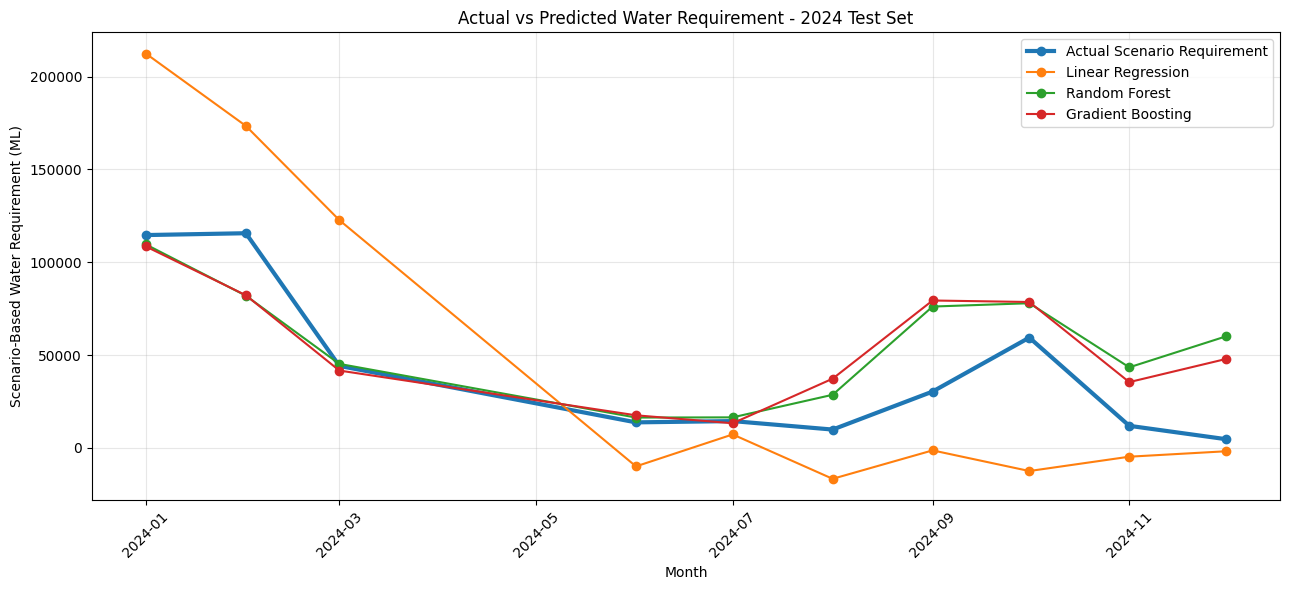

In [63]:
# ============================================================
# CELL 42: ACTUAL VS PREDICTED - MODEL COMPARISON GRAPH
# ============================================================

plt.figure(figsize=(13, 6))

plt.plot(
    test_results["Date"],
    test_results["Actual_ML"],
    marker="o",
    linewidth=3,
    label="Actual Scenario Requirement"
)

plt.plot(
    test_results["Date"],
    test_results["Linear_Regression_ML"],
    marker="o",
    label="Linear Regression"
)

plt.plot(
    test_results["Date"],
    test_results["Random_Forest_ML"],
    marker="o",
    label="Random Forest"
)

plt.plot(
    test_results["Date"],
    test_results["Gradient_Boosting_ML"],
    marker="o",
    label="Gradient Boosting"
)

plt.title(
    "Actual vs Predicted Water Requirement - 2024 Test Set"
)

plt.xlabel("Month")
plt.ylabel("Scenario-Based Water Requirement (ML)")

plt.legend()
plt.grid(alpha=0.3)

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

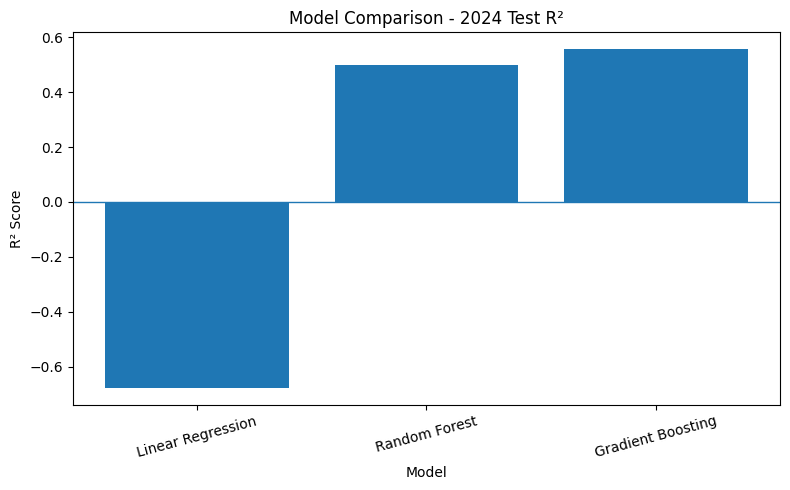

In [64]:
# ============================================================
# CELL 43: TEST R² COMPARISON
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    model_comparison["Model"],
    model_comparison["Test_R2"]
)

plt.axhline(
    y=0,
    linewidth=1
)

plt.title("Model Comparison - 2024 Test R²")
plt.ylabel("R² Score")
plt.xlabel("Model")

plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

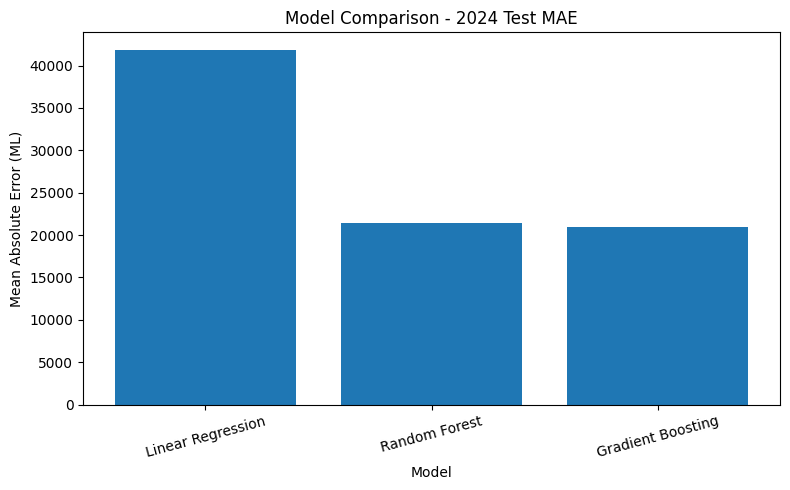

In [65]:
# ============================================================
# CELL 44: TEST MAE COMPARISON
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    model_comparison["Model"],
    model_comparison["Test_MAE_ML"]
)

plt.title("Model Comparison - 2024 Test MAE")
plt.ylabel("Mean Absolute Error (ML)")
plt.xlabel("Model")

plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

In [66]:
# ============================================================
# CELL 45: RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

rf_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": rf_model.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

print("RANDOM FOREST FEATURE IMPORTANCE")
print("=" * 50)

display(rf_importance.round(4))

RANDOM FOREST FEATURE IMPORTANCE


,Feature,Importance
2,Min_Temp_C,0.2973
3,Avg_Temp_C,0.2382
0,Rainfall_mm,0.1936
10,Month_Cos,0.0802
9,Month_Sin,0.0763
1,Max_Temp_C,0.0283
4,Avg_Humidity_pct,0.0232
7,Reservoir_Inflow_Processed_Cusecs,0.0224
8,Reservoir_Outflow_Processed_Cusecs,0.0197
5,GW_Level_Processed_m_bgl,0.0122


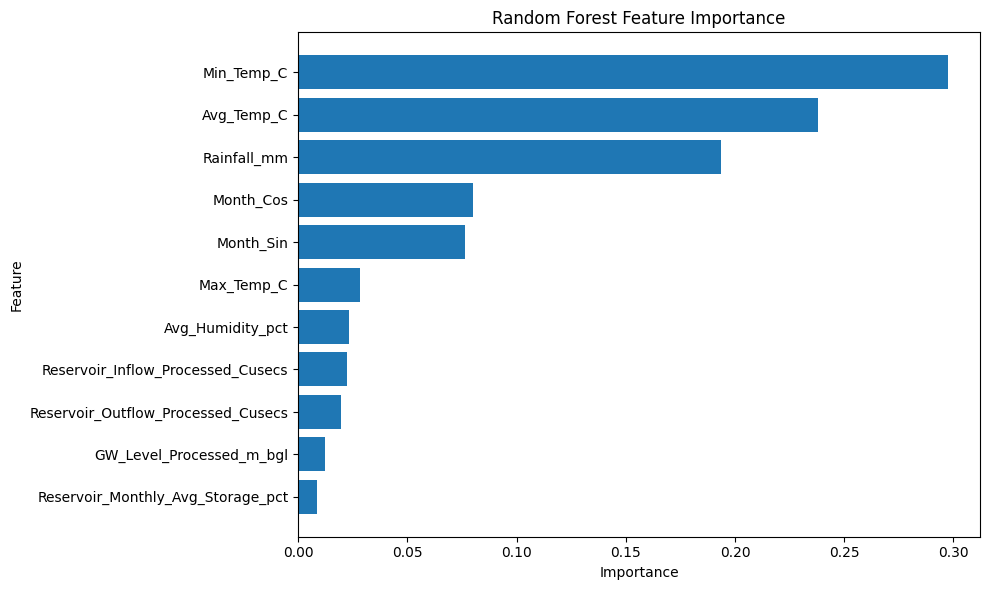

In [67]:
plt.figure(figsize=(10, 6))

plt.barh(
    rf_importance["Feature"],
    rf_importance["Importance"]
)

plt.gca().invert_yaxis()

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [68]:
# ============================================================
# CELL 46: GRADIENT BOOSTING FEATURE IMPORTANCE
# ============================================================

gb_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": gb_model.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

print("GRADIENT BOOSTING FEATURE IMPORTANCE")
print("=" * 50)

display(gb_importance.round(4))

GRADIENT BOOSTING FEATURE IMPORTANCE


,Feature,Importance
2,Min_Temp_C,0.3877
0,Rainfall_mm,0.1818
3,Avg_Temp_C,0.1463
7,Reservoir_Inflow_Processed_Cusecs,0.0864
9,Month_Sin,0.0823
10,Month_Cos,0.0667
6,Reservoir_Monthly_Avg_Storage_pct,0.0186
4,Avg_Humidity_pct,0.0132
5,GW_Level_Processed_m_bgl,0.0099
1,Max_Temp_C,0.0051


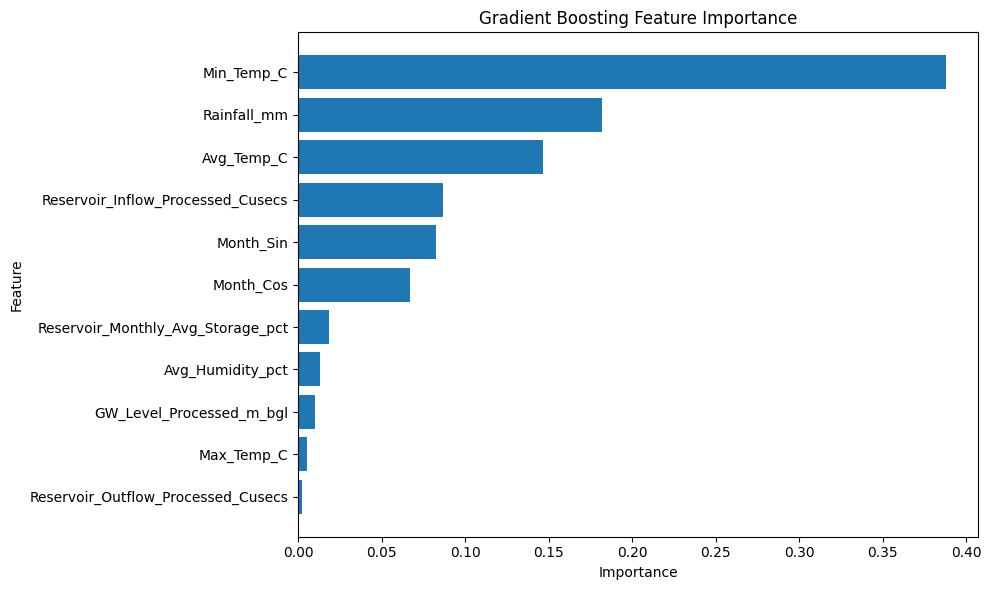

In [69]:
plt.figure(figsize=(10, 6))

plt.barh(
    gb_importance["Feature"],
    gb_importance["Importance"]
)

plt.gca().invert_yaxis()

plt.title("Gradient Boosting Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [70]:
# ============================================================
# CELL 47: FINAL MODEL SELECTION
# ============================================================

final_model = gb_model
final_model_name = "Gradient Boosting Regressor"

print("FINAL SELECTED MODEL")
print("=" * 50)

print("Model :", final_model_name)
print(f"Validation R² : {gb_val_metrics['R2']:.3f}")
print(f"Test R²       : {gb_test_metrics['R2']:.3f}")
print(f"Test MAE      : {gb_test_metrics['MAE']:.3f} ML")
print(f"Test RMSE     : {gb_test_metrics['RMSE']:.3f} ML")

print("\nReason for selection:")
print(
    "Gradient Boosting achieved the strongest performance "
    "on the unseen 2024 test period among the evaluated models, "
    "with the highest test R² and lowest test MAE and RMSE."
)

FINAL SELECTED MODEL
Model : Gradient Boosting Regressor
Validation R² : 0.714
Test R²       : 0.556
Test MAE      : 20939.840 ML
Test RMSE     : 26685.075 ML

Reason for selection:
Gradient Boosting achieved the strongest performance on the unseen 2024 test period among the evaluated models, with the highest test R² and lowest test MAE and RMSE.


In [71]:
# ============================================================
# CELL 48: 2025 DEMONSTRATION PREDICTIONS
# ============================================================

gb_2025_pred = final_model.predict(X_2025)

demo_2025_results = pd.DataFrame({
    "Date": ml_data.loc[demo_mask, "Date"].values,
    "Actual_Scenario_ML": y_2025.values,
    "Predicted_ML": gb_2025_pred
})

demo_2025_results["Absolute_Error_ML"] = abs(
    demo_2025_results["Actual_Scenario_ML"]
    - demo_2025_results["Predicted_ML"]
)

print("2025 DEMONSTRATION - GRADIENT BOOSTING")
print("=" * 60)

display(demo_2025_results.round(2))

2025 DEMONSTRATION - GRADIENT BOOSTING


,Date,Actual_Scenario_ML,Predicted_ML,Absolute_Error_ML
0,2025-01-01,115473.12,106402.34,9070.78
1,2025-02-01,135665.84,87473.39,48192.45
2,2025-03-01,4725.78,77563.44,72837.66


In [72]:
# ============================================================
# CELL 49: 2025 DEMONSTRATION METRICS
# ============================================================

gb_2025_metrics = evaluate_model(
    y_2025,
    gb_2025_pred
)

print("GRADIENT BOOSTING - 2025 DEMONSTRATION")
print("=" * 50)

print(f"Number of observations : {len(y_2025)}")
print(f"MAE   : {gb_2025_metrics['MAE']:.3f} ML")
print(f"RMSE  : {gb_2025_metrics['RMSE']:.3f} ML")
print(f"R²    : {gb_2025_metrics['R2']:.3f}")
print(f"MAPE  : {gb_2025_metrics['MAPE']:.3f}%")

print("\nNote:")
print(
    "2025 contains only 3 target-available months. "
    "These results are presented as a demonstration and "
    "not as the primary model evaluation."
)

GRADIENT BOOSTING - 2025 DEMONSTRATION
Number of observations : 3
MAE   : 43366.964 ML
RMSE  : 50695.548 ML
R²    : 0.224
MAPE  : 528.220%

Note:
2025 contains only 3 target-available months. These results are presented as a demonstration and not as the primary model evaluation.


In [74]:
# ============================================================
# CELL 51: INSPECT 2025 PREDICTION ERRORS
# ============================================================

demo_2025_results["Error_ML"] = (
    demo_2025_results["Predicted_ML"]
    - demo_2025_results["Actual_Scenario_ML"]
)

demo_2025_results["Error_pct"] = (
    demo_2025_results["Error_ML"].abs()
    / demo_2025_results["Actual_Scenario_ML"]
) * 100

print("2025 MONTH-WISE PREDICTION ANALYSIS")
print("=" * 70)

display(
    demo_2025_results[
        [
            "Date",
            "Actual_Scenario_ML",
            "Predicted_ML",
            "Error_ML",
            "Absolute_Error_ML",
            "Error_pct"
        ]
    ].round(2)
)

2025 MONTH-WISE PREDICTION ANALYSIS


,Date,Actual_Scenario_ML,Predicted_ML,Error_ML,Absolute_Error_ML,Error_pct
0,2025-01-01,115473.12,106402.34,-9070.78,9070.78,7.86
1,2025-02-01,135665.84,87473.39,-48192.45,48192.45,35.52
2,2025-03-01,4725.78,77563.44,72837.66,72837.66,1541.28


In [75]:
# Compare 2024 and 2025 target ranges

print("2024 TEST TARGET")
print("-" * 40)
print(y_test.describe())

print("\n2025 DEMONSTRATION TARGET")
print("-" * 40)
print(y_2025.describe())

2024 TEST TARGET
----------------------------------------
count        10.000000
mean      41904.498646
std       42204.331216
min        4713.009985
25%       12375.049692
50%       22411.618616
75%       55620.402190
max      115655.090767
Name: Agri_Residential_Mid_Scenario_ML, dtype: float64

2025 DEMONSTRATION TARGET
----------------------------------------
count         3.000000
mean      85288.249162
std       70495.883271
min        4725.783857
25%       60099.453803
50%      115473.123750
75%      125569.481814
max      135665.839878
Name: Agri_Residential_Mid_Scenario_ML, dtype: float64


In [76]:
# ============================================================
# 2025 MONTH-WISE PREDICTION ERROR
# ============================================================

demo_2025_results["Error_ML"] = (
    demo_2025_results["Predicted_ML"]
    - demo_2025_results["Actual_Scenario_ML"]
)

demo_2025_results["Error_pct"] = (
    demo_2025_results["Absolute_Error_ML"]
    / demo_2025_results["Actual_Scenario_ML"]
) * 100

display(
    demo_2025_results[
        [
            "Date",
            "Actual_Scenario_ML",
            "Predicted_ML",
            "Absolute_Error_ML",
            "Error_ML",
            "Error_pct"
        ]
    ].round(2)
)

,Date,Actual_Scenario_ML,Predicted_ML,Absolute_Error_ML,Error_ML,Error_pct
0,2025-01-01,115473.12,106402.34,9070.78,-9070.78,7.86
1,2025-02-01,135665.84,87473.39,48192.45,-48192.45,35.52
2,2025-03-01,4725.78,77563.44,72837.66,72837.66,1541.28


In [80]:
for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(name, obj.shape)

_ (11, 3)
___ (30, 10)
monthly (132, 55)
_3 (5, 50)
_5 (15, 4)
ml_data (100, 57)
_9 (12, 4)
X (100, 11)
X_train (77, 11)
X_val (10, 11)
X_test (10, 11)
X_future (3, 11)
check_2025 (12, 4)
_13 (12, 4)
_14 (12, 4)
gb_comparison (4, 7)
_20 (4, 7)
_23 (5, 50)
agri_existing (132, 3)
agri_scenario (132, 12)
_29 (30, 10)
zero_agri (44, 6)
zero_check (44, 8)
year_check (11, 3)
_36 (11, 3)
check_2024_2025 (24, 7)
agri_corrected (132, 3)
target_availability (11, 2)
final_target_check (24, 5)
X_2025 (3, 11)
model_comparison (3, 8)
test_results (10, 8)
rf_importance (11, 2)
gb_importance (11, 2)
demo_2025_results (3, 6)


In [81]:
# ============================================================
# ANOMALY DETECTION USING ISOLATION FOREST
# Uses full monthly dataset: 2015-2025 (132 months)
# ============================================================

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

# Features for anomaly detection
anomaly_features = [
    "Rainfall_mm",
    "Avg_Temp_C",
    "Avg_Humidity_pct",
    "GW_Level_Processed_m_bgl",
    "Reservoir_Monthly_Avg_Storage_pct",
    "Reservoir_Inflow_Processed_Cusecs",
    "Reservoir_Outflow_Processed_Cusecs"
]

# Create anomaly dataset from existing monthly dataframe
anomaly_df = monthly[
    ["Date", "Year", "Month"] + anomaly_features
].copy()

# Make sure Date is datetime
anomaly_df["Date"] = pd.to_datetime(anomaly_df["Date"])

# Check missing values
print("Missing values:")
print(anomaly_df[anomaly_features].isnull().sum())

print("\nTotal monthly records:", len(anomaly_df))

Missing values:
Rainfall_mm                           0
Avg_Temp_C                            0
Avg_Humidity_pct                      0
GW_Level_Processed_m_bgl              0
Reservoir_Monthly_Avg_Storage_pct     0
Reservoir_Inflow_Processed_Cusecs     0
Reservoir_Outflow_Processed_Cusecs    0
dtype: int64

Total monthly records: 132


In [82]:
# ============================================================
# STEP 2: STANDARDIZATION + ISOLATION FOREST
# ============================================================

# Standardize the 7 input features
scaler_anomaly = StandardScaler()

X_anomaly = scaler_anomaly.fit_transform(
    anomaly_df[anomaly_features]
)

print("Shape after standardization:", X_anomaly.shape)


# Create Isolation Forest model
iso_model = IsolationForest(
    n_estimators=300,
    contamination=0.05,
    random_state=42
)

# Train model and predict
anomaly_df["IF_Label"] = iso_model.fit_predict(X_anomaly)

# Convert output into readable labels
anomaly_df["Status"] = np.where(
    anomaly_df["IF_Label"] == -1,
    "Anomaly",
    "Normal"
)

# Calculate anomaly score
# Larger positive value = more unusual
anomaly_df["Anomaly_Score"] = -iso_model.decision_function(
    X_anomaly
)

# Summary
print("\nIsolation Forest Results")
print("------------------------")
print("Total months :", len(anomaly_df))
print("Normal months:",
      (anomaly_df["Status"] == "Normal").sum())
print("Anomaly months:",
      (anomaly_df["Status"] == "Anomaly").sum())

Shape after standardization: (132, 7)

Isolation Forest Results
------------------------
Total months : 132
Normal months: 125
Anomaly months: 7


In [83]:
# ============================================================
# STEP 3: DISPLAY DETECTED ANOMALIES
# ============================================================

# Select only anomalous months
anomalies = anomaly_df[
    anomaly_df["Status"] == "Anomaly"
].copy()

# Rank strongest anomaly first
anomalies = anomalies.sort_values(
    by="Anomaly_Score",
    ascending=False
)

# Select important columns
anomaly_results = anomalies[
    [
        "Date",
        "Rainfall_mm",
        "Avg_Temp_C",
        "Avg_Humidity_pct",
        "GW_Level_Processed_m_bgl",
        "Reservoir_Monthly_Avg_Storage_pct",
        "Reservoir_Inflow_Processed_Cusecs",
        "Reservoir_Outflow_Processed_Cusecs",
        "Anomaly_Score"
    ]
].copy()

# Round values for readability
anomaly_results = anomaly_results.round(3)

# Add rank
anomaly_results.insert(
    0,
    "Rank",
    range(1, len(anomaly_results) + 1)
)

display(anomaly_results)

,Rank,Date,Rainfall_mm,Avg_Temp_C,Avg_Humidity_pct,GW_Level_Processed_m_bgl,Reservoir_Monthly_Avg_Storage_pct,Reservoir_Inflow_Processed_Cusecs,Reservoir_Outflow_Processed_Cusecs,Anomaly_Score
107,1,2023-12-01,498.1,28.55,82.5,2.825,99.675,11700.000,9250.000,0.142
108,2,2024-01-01,19.8,26.85,82.5,0.850,92.303,10028.571,7928.571,0.039
106,3,2023-11-01,48.3,27.80,84.5,4.800,94.914,10840.577,8586.538,0.032
82,4,2021-11-01,405.1,27.70,88.0,1.200,85.560,3250.000,1475.000,0.025
105,5,2023-10-01,48.3,28.15,83.5,5.860,90.153,9981.154,7923.077,0.008
104,6,2023-09-01,35.5,31.30,74.0,6.920,85.393,9121.731,7259.615,0.008
10,7,2015-11-01,384.2,27.15,86.0,2.980,95.360,3032.500,2500.000,0.002


In [84]:
# ============================================================
# STEP 4: ANALYSE WHY EACH ANOMALY WAS DETECTED
# ============================================================

# Add standardized feature values to anomaly_df
for i, feature in enumerate(anomaly_features):
    anomaly_df[feature + "_Z"] = X_anomaly[:, i]

# Get anomalous months
anomaly_explanation = anomaly_df[
    anomaly_df["Status"] == "Anomaly"
].copy()

# Sort strongest anomaly first
anomaly_explanation = anomaly_explanation.sort_values(
    "Anomaly_Score",
    ascending=False
)

# Function to identify strongest unusual variables
def explain_anomaly(row):

    deviations = {}

    for feature in anomaly_features:
        deviations[feature] = abs(row[feature + "_Z"])

    # Sort according to largest deviation
    top_features = sorted(
        deviations,
        key=deviations.get,
        reverse=True
    )[:3]

    explanations = []

    for feature in top_features:

        z = row[feature + "_Z"]

        direction = "High" if z > 0 else "Low"

        explanations.append(
            f"{feature}: {direction} ({z:.2f} SD)"
        )

    return "; ".join(explanations)


# Generate explanation
anomaly_explanation["Main_Anomaly_Drivers"] = (
    anomaly_explanation.apply(
        explain_anomaly,
        axis=1
    )
)


# Display result
display(
    anomaly_explanation[
        [
            "Date",
            "Anomaly_Score",
            "Main_Anomaly_Drivers"
        ]
    ].round(3)
)

,Date,Anomaly_Score,Main_Anomaly_Drivers
107,2023-12-01,0.142,Rainfall_mm: High (5.38 SD); Reservoir_Outflow...
108,2024-01-01,0.039,Reservoir_Outflow_Processed_Cusecs: High (3.51...
106,2023-11-01,0.032,Reservoir_Outflow_Processed_Cusecs: High (3.87...
82,2021-11-01,0.025,Rainfall_mm: High (4.26 SD); Avg_Humidity_pct:...
105,2023-10-01,0.008,Reservoir_Outflow_Processed_Cusecs: High (3.50...
104,2023-09-01,0.008,Reservoir_Outflow_Processed_Cusecs: High (3.14...
10,2015-11-01,0.002,Rainfall_mm: High (4.00 SD); Avg_Humidity_pct:...


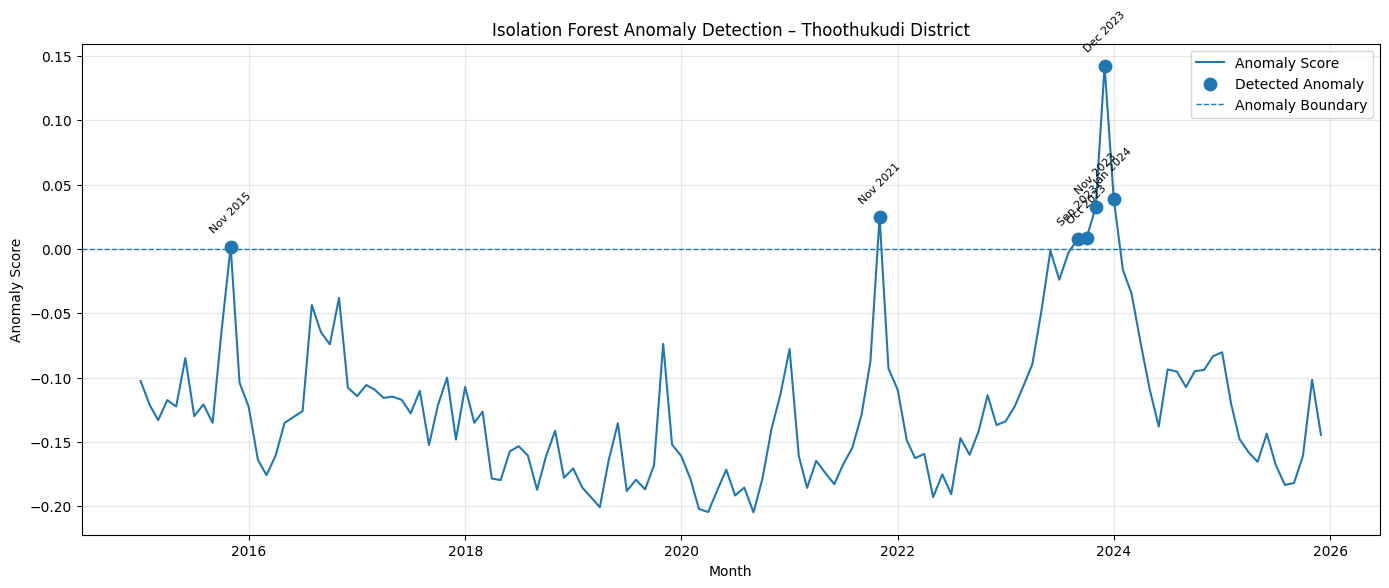

In [85]:
# ============================================================
# VISUAL REPRESENTATION OF ANOMALY DETECTION
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

# Plot anomaly score for all months
plt.plot(
    anomaly_df["Date"],
    anomaly_df["Anomaly_Score"],
    linewidth=1.5,
    label="Anomaly Score"
)

# Highlight detected anomalies
plt.scatter(
    anomalies["Date"],
    anomalies["Anomaly_Score"],
    s=80,
    marker="o",
    label="Detected Anomaly",
    zorder=5
)

# Decision boundary
plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1,
    label="Anomaly Boundary"
)

# Label anomalous months
for _, row in anomalies.iterrows():

    label = row["Date"].strftime("%b %Y")

    plt.annotate(
        label,
        (row["Date"], row["Anomaly_Score"]),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        rotation=45
    )

plt.title(
    "Isolation Forest Anomaly Detection – Thoothukudi District"
)

plt.xlabel("Month")
plt.ylabel("Anomaly Score")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

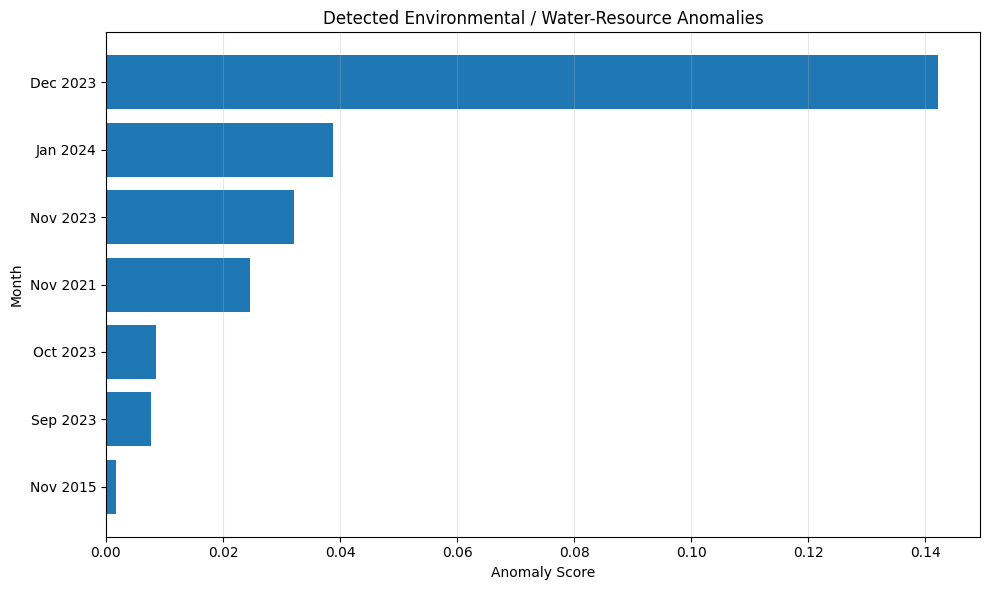

In [86]:
# ============================================================
# BAR CHART - DETECTED ANOMALIES ONLY
# ============================================================

plot_anomalies = anomalies.copy()

plot_anomalies["Month_Label"] = (
    plot_anomalies["Date"].dt.strftime("%b %Y")
)

plot_anomalies = plot_anomalies.sort_values(
    "Anomaly_Score",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_anomalies["Month_Label"],
    plot_anomalies["Anomaly_Score"]
)

plt.xlabel("Anomaly Score")
plt.ylabel("Month")

plt.title(
    "Detected Environmental / Water-Resource Anomalies"
)

plt.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()
plt.show()

In [87]:
# ============================================================
# WATER STRESS CLASSIFICATION
# STEP 1: CALCULATE HISTORICAL THRESHOLDS
# ============================================================

# 25th percentile thresholds
rainfall_q25 = monthly["Rainfall_mm"].quantile(0.25)

reservoir_q25 = monthly[
    "Reservoir_Monthly_Avg_Storage_pct"
].quantile(0.25)

# 75th percentile thresholds
groundwater_q75 = monthly[
    "GW_Level_Processed_m_bgl"
].quantile(0.75)

temperature_q75 = monthly[
    "Avg_Temp_C"
].quantile(0.75)


print("WATER STRESS THRESHOLDS")
print("-----------------------")

print(
    f"Low Rainfall Threshold (Q25): "
    f"{rainfall_q25:.2f} mm"
)

print(
    f"Low Reservoir Storage Threshold (Q25): "
    f"{reservoir_q25:.2f} %"
)

print(
    f"Deep Groundwater Threshold (Q75): "
    f"{groundwater_q75:.2f} m bgl"
)

print(
    f"High Temperature Threshold (Q75): "
    f"{temperature_q75:.2f} °C"
)

WATER STRESS THRESHOLDS
-----------------------
Low Rainfall Threshold (Q25): 8.35 mm
Low Reservoir Storage Threshold (Q25): 49.39 %
Deep Groundwater Threshold (Q75): 7.16 m bgl
High Temperature Threshold (Q75): 31.20 °C


In [88]:
# ============================================================
# WATER STRESS CLASSIFICATION
# STEP 2: CALCULATE MONTHLY WATER STRESS SCORE
# ============================================================

# Create a separate dataframe for water stress analysis
water_stress = monthly.copy()

# Individual stress indicators
water_stress["Low_Rainfall"] = (
    water_stress["Rainfall_mm"] <= rainfall_q25
).astype(int)

water_stress["Low_Reservoir"] = (
    water_stress["Reservoir_Monthly_Avg_Storage_pct"] <= reservoir_q25
).astype(int)

water_stress["Deep_Groundwater"] = (
    water_stress["GW_Level_Processed_m_bgl"] >= groundwater_q75
).astype(int)

water_stress["High_Temperature"] = (
    water_stress["Avg_Temp_C"] >= temperature_q75
).astype(int)


# Total Water Stress Score
water_stress["Water_Stress_Score"] = (
    water_stress["Low_Rainfall"]
    + water_stress["Low_Reservoir"]
    + water_stress["Deep_Groundwater"]
    + water_stress["High_Temperature"]
)


# Convert score into stress category
def classify_water_stress(score):
    if score == 0:
        return "Low"
    elif score == 1:
        return "Moderate"
    elif score == 2:
        return "High"
    else:
        return "Critical"


water_stress["Water_Stress_Level"] = (
    water_stress["Water_Stress_Score"]
    .apply(classify_water_stress)
)


# Display summary
print("WATER STRESS CLASSIFICATION SUMMARY")
print("-----------------------------------")

print(
    water_stress["Water_Stress_Level"]
    .value_counts()
    .reindex(
        ["Low", "Moderate", "High", "Critical"],
        fill_value=0
    )
)

print("\nMaximum Water Stress Score:",
      water_stress["Water_Stress_Score"].max())

WATER STRESS CLASSIFICATION SUMMARY
-----------------------------------
Water_Stress_Level
Low         55
Moderate    35
High        30
Critical    12
Name: count, dtype: int64

Maximum Water Stress Score: 4


In [89]:
# ============================================================
# DISPLAY HIGHEST WATER-STRESS MONTHS
# ============================================================

stress_results = water_stress[
    [
        "Date",
        "Rainfall_mm",
        "Reservoir_Monthly_Avg_Storage_pct",
        "GW_Level_Processed_m_bgl",
        "Avg_Temp_C",
        "Low_Rainfall",
        "Low_Reservoir",
        "Deep_Groundwater",
        "High_Temperature",
        "Water_Stress_Score",
        "Water_Stress_Level"
    ]
].copy()

stress_results = stress_results.sort_values(
    ["Water_Stress_Score", "Date"],
    ascending=[False, True]
)

display(stress_results.head(20))

,Date,Rainfall_mm,Reservoir_Monthly_Avg_Storage_pct,GW_Level_Processed_m_bgl,Avg_Temp_C,Low_Rainfall,Low_Reservoir,Deep_Groundwater,High_Temperature,Water_Stress_Score,Water_Stress_Level
17,2016-06-01,0.70,35.892500,9.243333,31.25,1,1,1,1,4,Critical
20,2016-09-01,0.40,17.687333,9.686667,31.85,1,1,1,1,4,Critical
27,2017-04-01,1.50,29.008667,10.112500,31.20,1,1,1,1,4,Critical
16,2016-05-01,22.90,45.803750,8.970000,31.75,0,1,1,1,3,Critical
18,2016-07-01,16.40,25.981250,9.516667,31.60,0,1,1,1,3,Critical
19,2016-08-01,0.50,16.070000,9.790000,29.45,1,1,1,0,3,Critical
25,2017-02-01,0.04,25.774000,9.404167,27.35,1,1,1,0,3,Critical
28,2017-05-01,15.00,30.626000,10.466667,31.70,0,1,1,1,3,Critical
29,2017-06-01,11.20,32.243333,10.591111,31.65,0,1,1,1,3,Critical
41,2018-06-01,4.20,46.908864,6.244762,31.93,1,1,0,1,3,Critical


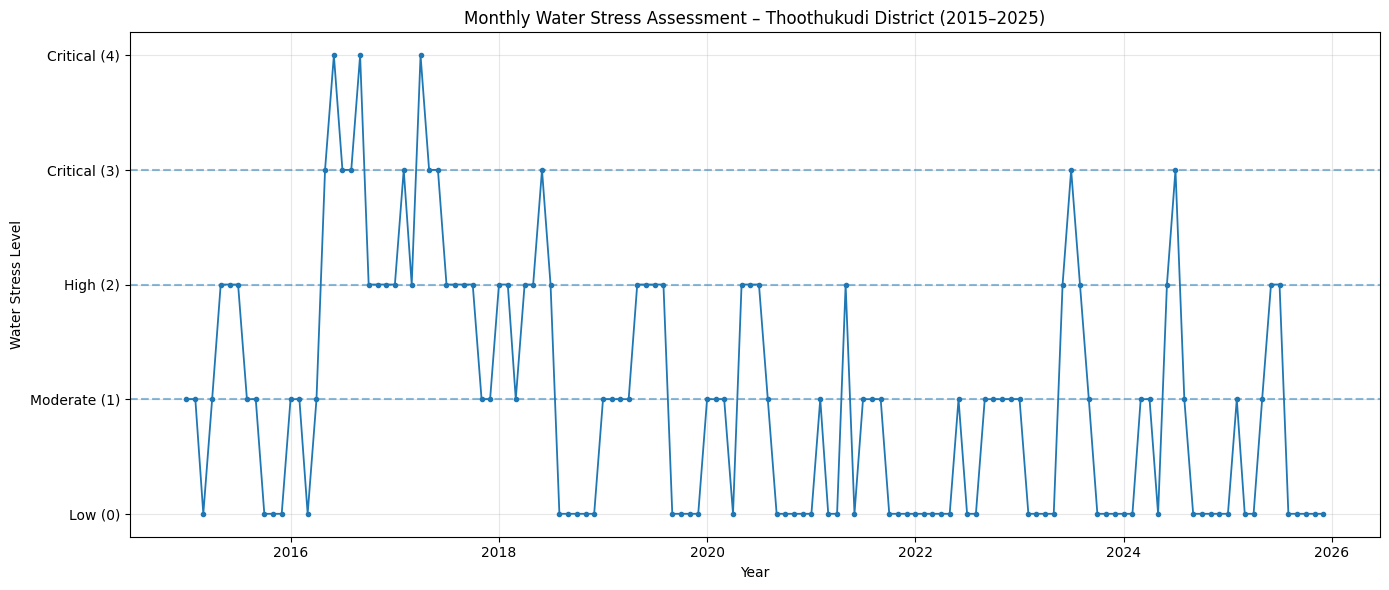

In [90]:
# ============================================================
# VISUAL 1: MONTHLY WATER STRESS TREND
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    water_stress["Date"],
    water_stress["Water_Stress_Score"],
    marker="o",
    markersize=3,
    linewidth=1.3
)

# Stress level reference lines
plt.axhline(y=1, linestyle="--", alpha=0.5)
plt.axhline(y=2, linestyle="--", alpha=0.5)
plt.axhline(y=3, linestyle="--", alpha=0.5)

plt.yticks(
    [0, 1, 2, 3, 4],
    ["Low (0)", "Moderate (1)", "High (2)",
     "Critical (3)", "Critical (4)"]
)

plt.title(
    "Monthly Water Stress Assessment – Thoothukudi District (2015–2025)"
)

plt.xlabel("Year")
plt.ylabel("Water Stress Level")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

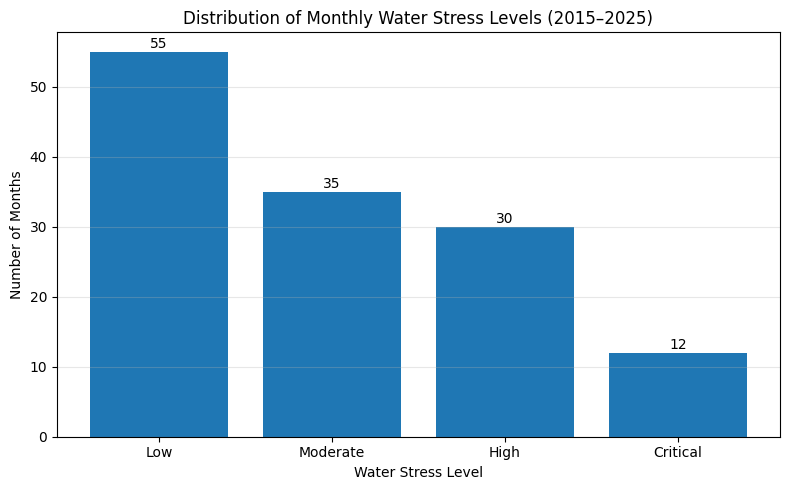

In [91]:
# ============================================================
# VISUAL 2: WATER STRESS LEVEL DISTRIBUTION
# ============================================================

stress_order = ["Low", "Moderate", "High", "Critical"]

stress_counts = (
    water_stress["Water_Stress_Level"]
    .value_counts()
    .reindex(stress_order, fill_value=0)
)

plt.figure(figsize=(8, 5))

bars = plt.bar(
    stress_counts.index,
    stress_counts.values
)

# Add count above each bar
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.5,
        str(int(height)),
        ha="center"
    )

plt.title(
    "Distribution of Monthly Water Stress Levels (2015–2025)"
)

plt.xlabel("Water Stress Level")
plt.ylabel("Number of Months")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

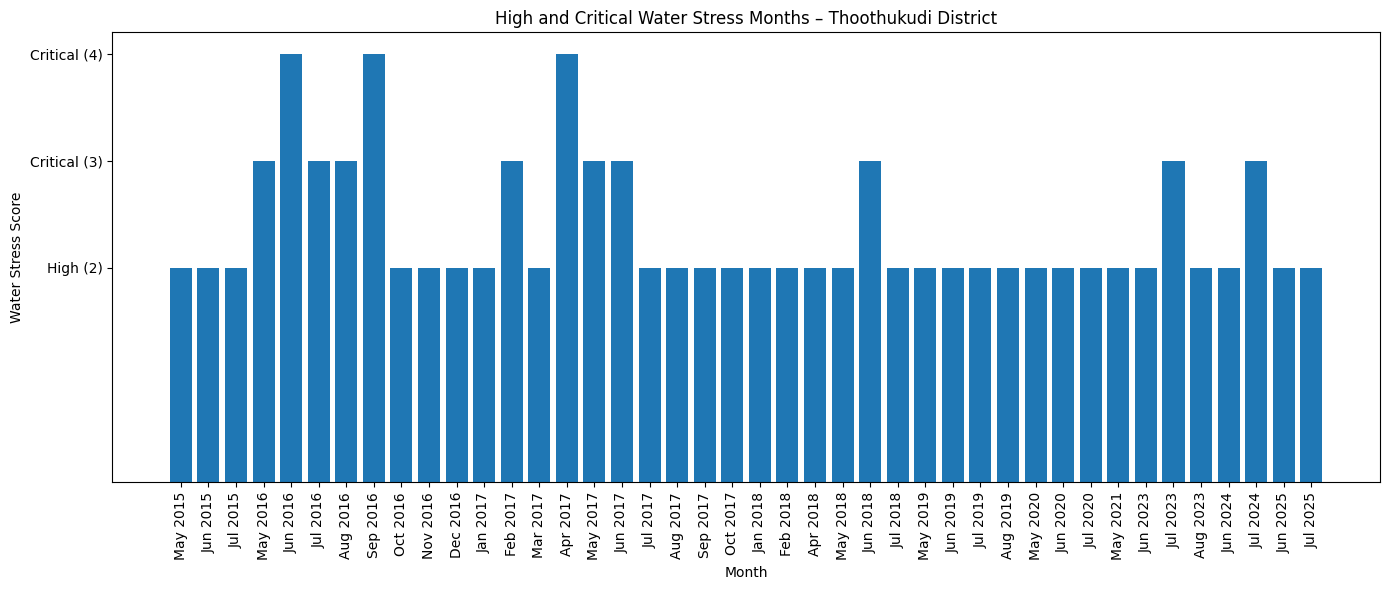

In [92]:
# ============================================================
# VISUAL 3: HIGH AND CRITICAL WATER STRESS MONTHS
# ============================================================

severe_stress = water_stress[
    water_stress["Water_Stress_Level"].isin(
        ["High", "Critical"]
    )
].copy()

plt.figure(figsize=(14, 6))

plt.bar(
    severe_stress["Date"].dt.strftime("%b %Y"),
    severe_stress["Water_Stress_Score"]
)

plt.xticks(rotation=90)

plt.yticks(
    [2, 3, 4],
    ["High (2)", "Critical (3)", "Critical (4)"]
)

plt.title(
    "High and Critical Water Stress Months – Thoothukudi District"
)

plt.xlabel("Month")
plt.ylabel("Water Stress Score")

plt.tight_layout()
plt.show()

In [93]:
# ============================================================
# CONSERVATION RECOMMENDATION SYSTEM
# ============================================================

def generate_recommendation(row):

    recommendations = []

    # Low rainfall
    if row["Low_Rainfall"] == 1:
        recommendations.append(
            "Promote rainwater harvesting and reduce non-essential water use"
        )

    # Low reservoir storage
    if row["Low_Reservoir"] == 1:
        recommendations.append(
            "Prioritize essential water supply and monitor reservoir releases"
        )

    # Deep groundwater
    if row["Deep_Groundwater"] == 1:
        recommendations.append(
            "Limit groundwater extraction and promote groundwater recharge"
        )

    # High temperature
    if row["High_Temperature"] == 1:
        recommendations.append(
            "Improve irrigation scheduling and reduce evaporation losses"
        )

    # No major stress condition
    if len(recommendations) == 0:
        recommendations.append(
            "Maintain normal monitoring and water-conservation practices"
        )

    return "; ".join(recommendations)


# Generate recommendations for every month
water_stress["Conservation_Recommendation"] = (
    water_stress.apply(
        generate_recommendation,
        axis=1
    )
)


# Display High and Critical stress months
recommendation_results = water_stress[
    water_stress["Water_Stress_Level"].isin(
        ["High", "Critical"]
    )
][
    [
        "Date",
        "Water_Stress_Score",
        "Water_Stress_Level",
        "Conservation_Recommendation"
    ]
].copy()


recommendation_results = recommendation_results.sort_values(
    ["Water_Stress_Score", "Date"],
    ascending=[False, True]
)

display(recommendation_results.head(20))

,Date,Water_Stress_Score,Water_Stress_Level,Conservation_Recommendation
17,2016-06-01,4,Critical,Promote rainwater harvesting and reduce non-es...
20,2016-09-01,4,Critical,Promote rainwater harvesting and reduce non-es...
27,2017-04-01,4,Critical,Promote rainwater harvesting and reduce non-es...
16,2016-05-01,3,Critical,Prioritize essential water supply and monitor ...
18,2016-07-01,3,Critical,Prioritize essential water supply and monitor ...
19,2016-08-01,3,Critical,Promote rainwater harvesting and reduce non-es...
25,2017-02-01,3,Critical,Promote rainwater harvesting and reduce non-es...
28,2017-05-01,3,Critical,Prioritize essential water supply and monitor ...
29,2017-06-01,3,Critical,Prioritize essential water supply and monitor ...
41,2018-06-01,3,Critical,Promote rainwater harvesting and reduce non-es...


In [94]:
# ============================================================
# FINAL DECISION-SUPPORT OUTPUT
# ============================================================

decision_support = water_stress[
    [
        "Date",
        "Rainfall_mm",
        "Reservoir_Monthly_Avg_Storage_pct",
        "GW_Level_Processed_m_bgl",
        "Water_Stress_Score",
        "Water_Stress_Level",
        "Conservation_Recommendation"
    ]
].copy()


# Add anomaly detection result
anomaly_info = anomaly_df[
    [
        "Date",
        "Status",
        "Anomaly_Score"
    ]
].copy()

anomaly_info = anomaly_info.rename(
    columns={
        "Status": "Anomaly_Status"
    }
)


decision_support = decision_support.merge(
    anomaly_info,
    on="Date",
    how="left"
)


# Reorder columns
decision_support = decision_support[
    [
        "Date",
        "Rainfall_mm",
        "Reservoir_Monthly_Avg_Storage_pct",
        "GW_Level_Processed_m_bgl",
        "Anomaly_Status",
        "Anomaly_Score",
        "Water_Stress_Score",
        "Water_Stress_Level",
        "Conservation_Recommendation"
    ]
]


print("Decision-Support Dataset Shape:",
      decision_support.shape)

display(
    decision_support.tail(12)
)

Decision-Support Dataset Shape: (132, 9)


,Date,Rainfall_mm,Reservoir_Monthly_Avg_Storage_pct,GW_Level_Processed_m_bgl,Anomaly_Status,Anomaly_Score,Water_Stress_Score,Water_Stress_Level,Conservation_Recommendation
120,2025-01-01,26.5,66.415000,1.6000,Normal,-0.080368,0,Low,Maintain normal monitoring and water-conservat...
121,2025-02-01,2.4,67.998056,2.4375,Normal,-0.121021,1,Moderate,Promote rainwater harvesting and reduce non-es...
122,2025-03-01,76.5,69.581111,3.2750,Normal,-0.147892,0,Low,Maintain normal monitoring and water-conservat...
123,2025-04-01,64.6,71.164167,4.1125,Normal,-0.158225,0,Low,Maintain normal monitoring and water-conservat...
124,2025-05-01,18.1,72.747222,4.9500,Normal,-0.165531,1,Moderate,Improve irrigation scheduling and reduce evapo...
125,2025-06-01,5.4,74.330278,5.1000,Normal,-0.143635,2,High,Promote rainwater harvesting and reduce non-es...
126,2025-07-01,2.1,75.913333,5.2500,Normal,-0.167798,2,High,Promote rainwater harvesting and reduce non-es...
127,2025-08-01,11.2,75.913333,5.4000,Normal,-0.183454,0,Low,Maintain normal monitoring and water-conservat...
128,2025-09-01,28.6,75.913333,5.4000,Normal,-0.181962,0,Low,Maintain normal monitoring and water-conservat...
129,2025-10-01,114.2,75.913333,5.4000,Normal,-0.160967,0,Low,Maintain normal monitoring and water-conservat...


In [95]:
# ============================================================
# DECISION-SUPPORT ALERT PRIORITY
# ============================================================

def assign_priority(row):

    # Highest priority
    if row["Water_Stress_Level"] == "Critical":
        return "Immediate Action"

    # High stress or unusual resource condition
    elif (
        row["Water_Stress_Level"] == "High"
        or row["Anomaly_Status"] == "Anomaly"
    ):
        return "High Attention"

    elif row["Water_Stress_Level"] == "Moderate":
        return "Monitor"

    else:
        return "Normal"


decision_support["Decision_Priority"] = (
    decision_support.apply(
        assign_priority,
        axis=1
    )
)


print("DECISION PRIORITY SUMMARY")
print("-------------------------")

print(
    decision_support["Decision_Priority"]
    .value_counts()
)

display(
    decision_support[
        decision_support["Decision_Priority"]
        == "Immediate Action"
    ][
        [
            "Date",
            "Anomaly_Status",
            "Water_Stress_Score",
            "Water_Stress_Level",
            "Decision_Priority",
            "Conservation_Recommendation"
        ]
    ]
)

DECISION PRIORITY SUMMARY
-------------------------
Decision_Priority
Normal              49
High Attention      37
Monitor             34
Immediate Action    12
Name: count, dtype: int64


,Date,Anomaly_Status,Water_Stress_Score,Water_Stress_Level,Decision_Priority,Conservation_Recommendation
16,2016-05-01,Normal,3,Critical,Immediate Action,Prioritize essential water supply and monitor ...
17,2016-06-01,Normal,4,Critical,Immediate Action,Promote rainwater harvesting and reduce non-es...
18,2016-07-01,Normal,3,Critical,Immediate Action,Prioritize essential water supply and monitor ...
19,2016-08-01,Normal,3,Critical,Immediate Action,Promote rainwater harvesting and reduce non-es...
20,2016-09-01,Normal,4,Critical,Immediate Action,Promote rainwater harvesting and reduce non-es...
25,2017-02-01,Normal,3,Critical,Immediate Action,Promote rainwater harvesting and reduce non-es...
27,2017-04-01,Normal,4,Critical,Immediate Action,Promote rainwater harvesting and reduce non-es...
28,2017-05-01,Normal,3,Critical,Immediate Action,Prioritize essential water supply and monitor ...
29,2017-06-01,Normal,3,Critical,Immediate Action,Prioritize essential water supply and monitor ...
41,2018-06-01,Normal,3,Critical,Immediate Action,Promote rainwater harvesting and reduce non-es...


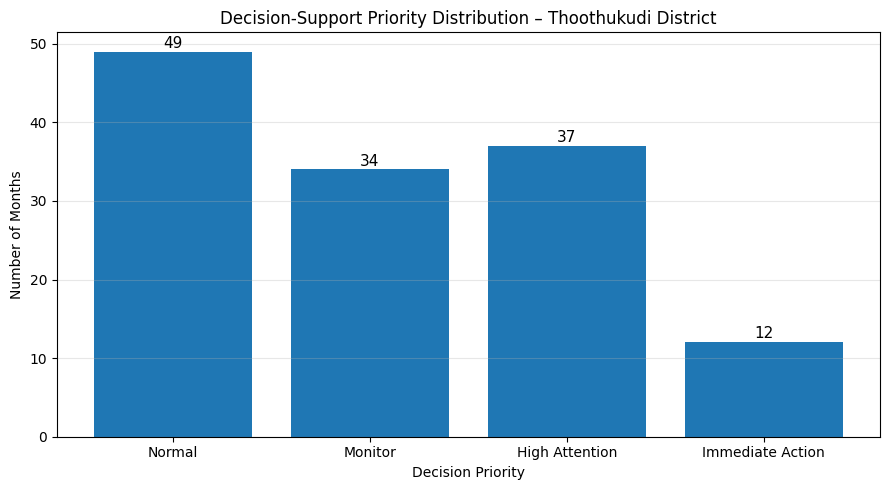

In [96]:
# ============================================================
# VISUAL: DECISION-SUPPORT PRIORITY DISTRIBUTION
# ============================================================

import matplotlib.pyplot as plt

priority_order = [
    "Normal",
    "Monitor",
    "High Attention",
    "Immediate Action"
]

priority_counts = (
    decision_support["Decision_Priority"]
    .value_counts()
    .reindex(priority_order, fill_value=0)
)

plt.figure(figsize=(9, 5))

bars = plt.bar(
    priority_counts.index,
    priority_counts.values
)

# Display count above each bar
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.5,
        str(int(height)),
        ha="center",
        fontsize=11
    )

plt.title(
    "Decision-Support Priority Distribution – Thoothukudi District"
)

plt.xlabel("Decision Priority")
plt.ylabel("Number of Months")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

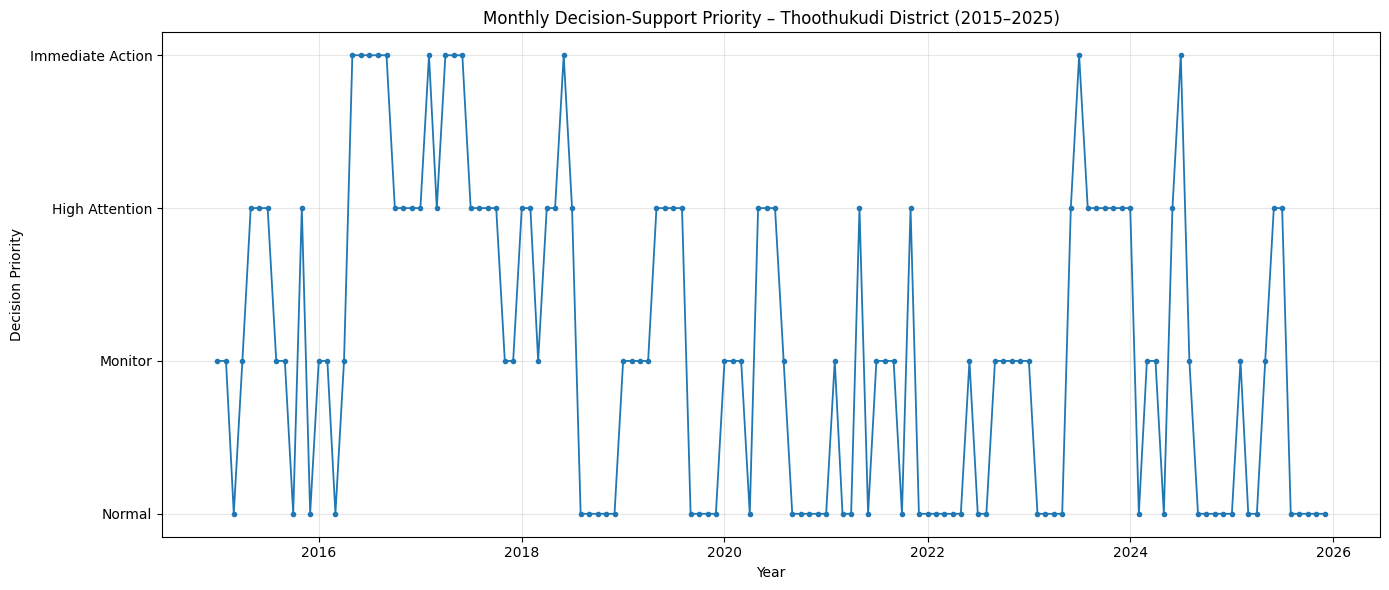

In [97]:
# ============================================================
# VISUAL: DECISION PRIORITY OVER TIME
# ============================================================

priority_map = {
    "Normal": 0,
    "Monitor": 1,
    "High Attention": 2,
    "Immediate Action": 3
}

decision_support["Priority_Score"] = (
    decision_support["Decision_Priority"]
    .map(priority_map)
)

plt.figure(figsize=(14, 6))

plt.plot(
    decision_support["Date"],
    decision_support["Priority_Score"],
    marker="o",
    markersize=3,
    linewidth=1.3
)

plt.yticks(
    [0, 1, 2, 3],
    [
        "Normal",
        "Monitor",
        "High Attention",
        "Immediate Action"
    ]
)

plt.title(
    "Monthly Decision-Support Priority – Thoothukudi District (2015–2025)"
)

plt.xlabel("Year")
plt.ylabel("Decision Priority")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [98]:
# ============================================================
# FUTURE DEMAND FORECASTING
# STEP 1: PREPARE MONTHLY DEMAND TIME SERIES
# ============================================================

demand_ts = ml_data[
    ["Date", "Agri_Residential_Mid_Scenario_ML"]
].copy()

demand_ts["Date"] = pd.to_datetime(demand_ts["Date"])

demand_ts = (
    demand_ts
    .sort_values("Date")
    .reset_index(drop=True)
)

# Rename target for easier handling
demand_ts = demand_ts.rename(
    columns={
        "Agri_Residential_Mid_Scenario_ML":
        "Water_Requirement_ML"
    }
)

print("DEMAND FORECASTING DATA")
print("-----------------------")
print("Number of available months:", len(demand_ts))
print(
    "Period:",
    demand_ts["Date"].min().strftime("%b %Y"),
    "to",
    demand_ts["Date"].max().strftime("%b %Y")
)

print(
    "Missing target values:",
    demand_ts["Water_Requirement_ML"].isna().sum()
)

display(demand_ts.tail(12))

DEMAND FORECASTING DATA
-----------------------
Number of available months: 100
Period: Jun 2015 to Mar 2025
Missing target values: 0


,Date,Water_Requirement_ML
88,2024-02-01,115655.090767
89,2024-03-01,44183.330327
90,2024-06-01,13769.080954
91,2024-07-01,14458.623935
92,2024-08-01,9895.270335
93,2024-09-01,30364.613297
94,2024-10-01,59432.759477
95,2024-11-01,11910.372604
96,2024-12-01,4713.009985
97,2025-01-01,115473.123750


In [99]:
# ============================================================
# STEP 2: CHECK MONTHLY CONTINUITY
# ============================================================

demand_ts["Month_Gap"] = (
    demand_ts["Date"]
    .diff()
    .dt.days
)

# Show gaps larger than approximately one month
gaps = demand_ts[
    demand_ts["Month_Gap"] > 35
][
    ["Date", "Month_Gap"]
]

print("Number of gaps:", len(gaps))

display(gaps)

Number of gaps: 9


,Date,Month_Gap
10,2016-06-01,92.0
20,2017-06-01,92.0
30,2018-06-01,92.0
40,2019-06-01,92.0
50,2020-06-01,92.0
60,2021-06-01,92.0
70,2022-06-01,92.0
80,2023-06-01,92.0
90,2024-06-01,92.0


In [100]:
# ============================================================
# FUTURE DEMAND FORECASTING
# STEP 3: BUILD CONTINUOUS MONTHLY TIME SERIES
# ============================================================

# Full monthly calendar from the existing monthly dataframe
demand_full = monthly[["Date"]].copy()

demand_full["Date"] = pd.to_datetime(demand_full["Date"])

demand_full = (
    demand_full
    .drop_duplicates("Date")
    .sort_values("Date")
    .reset_index(drop=True)
)

# Add available demand target
target_data = ml_data[
    ["Date", "Agri_Residential_Mid_Scenario_ML"]
].copy()

target_data["Date"] = pd.to_datetime(target_data["Date"])

target_data = target_data.rename(
    columns={
        "Agri_Residential_Mid_Scenario_ML":
        "Water_Requirement_ML"
    }
)

# Merge onto complete 132-month calendar
demand_full = demand_full.merge(
    target_data,
    on="Date",
    how="left"
)

print("CONTINUOUS DEMAND SERIES")
print("------------------------")
print("Total calendar months :", len(demand_full))
print(
    "Available demand months:",
    demand_full["Water_Requirement_ML"].notna().sum()
)
print(
    "Unavailable months     :",
    demand_full["Water_Requirement_ML"].isna().sum()
)

display(demand_full.head(15))

CONTINUOUS DEMAND SERIES
------------------------
Total calendar months : 132
Available demand months: 100
Unavailable months     : 32


,Date,Water_Requirement_ML
0,2015-01-01,NaN
1,2015-02-01,NaN
2,2015-03-01,NaN
3,2015-04-01,NaN
4,2015-05-01,NaN
5,2015-06-01,16941.580098
6,2015-07-01,16492.049734
7,2015-08-01,15541.614534
8,2015-09-01,42558.639526
9,2015-10-01,4598.045134


In [101]:
# ============================================================
# STEP 4: IDENTIFY MISSING TARGET MONTHS
# ============================================================

missing_demand = demand_full[
    demand_full["Water_Requirement_ML"].isna()
].copy()

missing_demand["Year"] = missing_demand["Date"].dt.year
missing_demand["Month"] = missing_demand["Date"].dt.month
missing_demand["Month_Name"] = (
    missing_demand["Date"].dt.strftime("%b")
)

print("Missing target months by calendar month:")
print(
    missing_demand["Month_Name"]
    .value_counts()
)

print("\nMissing target dates:")
display(
    missing_demand[
        ["Date", "Year", "Month_Name"]
    ]
)

Missing target months by calendar month:
Month_Name
Apr    11
May    11
Feb     1
Jan     1
Mar     1
Jun     1
Jul     1
Aug     1
Sep     1
Oct     1
Nov     1
Dec     1
Name: count, dtype: int64

Missing target dates:


,Date,Year,Month_Name
0,2015-01-01,2015,Jan
1,2015-02-01,2015,Feb
2,2015-03-01,2015,Mar
3,2015-04-01,2015,Apr
4,2015-05-01,2015,May
15,2016-04-01,2016,Apr
16,2016-05-01,2016,May
27,2017-04-01,2017,Apr
28,2017-05-01,2017,May
39,2018-04-01,2018,Apr


In [102]:
# ============================================================
# STEP 5: FIND AGRICULTURE & RESIDENTIAL TARGET COLUMNS
# ============================================================

print("AGRI_SCENARIO COLUMNS")
print("---------------------")

for col in agri_scenario.columns:
    print(col)

print("\n\nMONTHLY COLUMNS RELATED TO AGRICULTURE / RESIDENTIAL")
print("-----------------------------------------------------")

for col in monthly.columns:
    if any(
        word in col.lower()
        for word in [
            "agri",
            "residential",
            "population",
            "demand",
            "requirement"
        ]
    ):
        print(col)

AGRI_SCENARIO COLUMNS
---------------------
Date
Year
Month
Rainfall_mm
Gross_Crop_Water_Scenario_ML
Effective_Rainfall_Proxy_ML
Net_Agriculture_Water_Scenario_ML
Scenario_Value_Type
Scenario_Method
Final_Y_Status
Agri_Net_Water_Corrected_ML
Agri_Scenario_Status_Corrected


MONTHLY COLUMNS RELATED TO AGRICULTURE / RESIDENTIAL
-----------------------------------------------------
Annual_Agriculture_GW_Extraction_ML_Context
Agriculture_GW_Extraction_Processed_ML
Agri_Gross_Water_Scenario_ML
Agri_Effective_Rainfall_Proxy_ML
Agri_Net_Water_Scenario_ML
Agri_Scenario_Type
Agri_Scenario_Final_Y_Status
Residential_Lower_Scenario_Monthly_ML
Residential_Upper_Scenario_Monthly_ML
Residential_Mid_Scenario_Monthly_ML
Agri_plus_Residential_Lower_Scenario_ML
Agri_plus_Residential_Upper_Scenario_ML
Agri_plus_Residential_Mid_Scenario_ML
Agri_Net_Water_Corrected_ML
Agri_Scenario_Status_Corrected
Agri_Residential_Mid_Scenario_ML


In [103]:
# Check existing residential-related DataFrames

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        if any(
            word in name.lower()
            for word in ["residential", "agri", "sector"]
        ):
            print(name, obj.shape)

agri_existing (132, 3)
agri_scenario (132, 12)
zero_agri (44, 6)
agri_corrected (132, 3)


In [104]:
print("agri_existing columns:")
print(agri_existing.columns.tolist())

print("\nagri_scenario columns:")
print(agri_scenario.columns.tolist())

print("\nagri_corrected columns:")
print(agri_corrected.columns.tolist())

agri_existing columns:
['Date', 'Rainfall_mm', 'Agri_Net_Water_Scenario_ML']

agri_scenario columns:
['Date', 'Year', 'Month', 'Rainfall_mm', 'Gross_Crop_Water_Scenario_ML', 'Effective_Rainfall_Proxy_ML', 'Net_Agriculture_Water_Scenario_ML', 'Scenario_Value_Type', 'Scenario_Method', 'Final_Y_Status', 'Agri_Net_Water_Corrected_ML', 'Agri_Scenario_Status_Corrected']

agri_corrected columns:
['Date', 'Agri_Net_Water_Corrected_ML', 'Agri_Scenario_Status_Corrected']


In [105]:
display(agri_corrected.head(15))
display(agri_corrected.tail(15))

,Date,Agri_Net_Water_Corrected_ML,Agri_Scenario_Status_Corrected
0,2015-01-01,NaN,Agriculture scenario unavailable
1,2015-02-01,NaN,Agriculture scenario unavailable
2,2015-03-01,NaN,Agriculture scenario unavailable
3,2015-04-01,NaN,Agriculture scenario unavailable
4,2015-05-01,NaN,Agriculture scenario unavailable
5,2015-06-01,12491.859000,Estimated irrigation requirement
6,2015-07-01,11894.004600,Estimated irrigation requirement
7,2015-08-01,10943.569400,Estimated irrigation requirement
8,2015-09-01,38108.918429,Estimated irrigation requirement
9,2015-10-01,0.000000,Rainfall satisfied estimated crop requirement


,Date,Agri_Net_Water_Corrected_ML,Agri_Scenario_Status_Corrected
117,2024-10-01,54719.749493,Estimated irrigation requirement
118,2024-11-01,7349.395200,Estimated irrigation requirement
119,2024-12-01,0.000000,Rainfall satisfied estimated crop requirement
120,2025-01-01,110747.339893,Estimated irrigation requirement
121,2025-02-01,131397.389943,Estimated irrigation requirement
122,2025-03-01,0.000000,Rainfall satisfied estimated crop requirement
123,2025-04-01,NaN,Agriculture scenario unavailable
124,2025-05-01,NaN,Agriculture scenario unavailable
125,2025-06-01,NaN,Agriculture scenario unavailable
126,2025-07-01,NaN,Agriculture scenario unavailable


In [106]:
print("\nMissing values in agri_corrected:")
print(agri_corrected.isnull().sum())


Missing values in agri_corrected:
Date                               0
Agri_Net_Water_Corrected_ML       32
Agri_Scenario_Status_Corrected     0
dtype: int64


In [107]:
# ============================================================
# FUTURE AGRICULTURE WATER REQUIREMENT
# STEP 7: PREPARE FORECASTING DATA
# ============================================================

agri_forecast_data = agri_corrected[
    ["Date", "Agri_Net_Water_Corrected_ML"]
].copy()

agri_forecast_data["Date"] = pd.to_datetime(
    agri_forecast_data["Date"]
)

# Keep only authenticated/available agriculture scenarios
agri_model_data = agri_forecast_data.dropna(
    subset=["Agri_Net_Water_Corrected_ML"]
).copy()

# Time features
agri_model_data["Year"] = (
    agri_model_data["Date"].dt.year
)

agri_model_data["Month"] = (
    agri_model_data["Date"].dt.month
)

agri_model_data["Month_Sin"] = np.sin(
    2 * np.pi * agri_model_data["Month"] / 12
)

agri_model_data["Month_Cos"] = np.cos(
    2 * np.pi * agri_model_data["Month"] / 12
)

print("Agriculture observations:",
      len(agri_model_data))

print(
    "Period:",
    agri_model_data["Date"].min(),
    "to",
    agri_model_data["Date"].max()
)

display(agri_model_data.tail(15))

Agriculture observations: 100
Period: 2015-06-01 00:00:00 to 2025-03-01 00:00:00


,Date,Agri_Net_Water_Corrected_ML,Year,Month,Month_Sin,Month_Cos
106,2023-11-01,74477.812793,2023,11,-5.000000e-01,8.660254e-01
107,2023-12-01,0.000000,2023,12,-2.449294e-16,1.000000e+00
108,2024-01-01,109949.824793,2024,1,5.000000e-01,8.660254e-01
109,2024-02-01,111246.145943,2024,2,8.660254e-01,5.000000e-01
110,2024-03-01,39470.320343,2024,3,1.000000e+00,6.123234e-17
113,2024-06-01,9208.103550,2024,6,1.224647e-16,-1.000000e+00
114,2024-07-01,9745.613950,2024,7,-5.000000e-01,-8.660254e-01
115,2024-08-01,5182.260350,2024,8,-8.660254e-01,-5.000000e-01
116,2024-09-01,25803.635893,2024,9,-1.000000e+00,-1.836970e-16
117,2024-10-01,54719.749493,2024,10,-8.660254e-01,5.000000e-01


In [108]:
# ============================================================
# STEP 8: AGRICULTURE FORECAST BACK-TEST
# Train through 2023 -> Test on available 2024 months
# ============================================================

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

agri_features = [
    "Year",
    "Month_Sin",
    "Month_Cos"
]

# Chronological split
agri_train = agri_model_data[
    agri_model_data["Date"].dt.year <= 2023
].copy()

agri_test = agri_model_data[
    agri_model_data["Date"].dt.year == 2024
].copy()


X_agri_train = agri_train[agri_features]
y_agri_train = agri_train[
    "Agri_Net_Water_Corrected_ML"
]

X_agri_test = agri_test[agri_features]
y_agri_test = agri_test[
    "Agri_Net_Water_Corrected_ML"
]


# Train model
agri_forecast_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

agri_forecast_model.fit(
    X_agri_train,
    y_agri_train
)


# Predict 2024
agri_test["Predicted_Agri_ML"] = (
    agri_forecast_model.predict(X_agri_test)
)

# Agriculture requirement cannot be negative
agri_test["Predicted_Agri_ML"] = (
    agri_test["Predicted_Agri_ML"].clip(lower=0)
)


# Evaluation
mae = mean_absolute_error(
    y_agri_test,
    agri_test["Predicted_Agri_ML"]
)

rmse = np.sqrt(
    mean_squared_error(
        y_agri_test,
        agri_test["Predicted_Agri_ML"]
    )
)

r2 = r2_score(
    y_agri_test,
    agri_test["Predicted_Agri_ML"]
)


print("AGRICULTURE FORECAST BACK-TEST – 2024")
print("-------------------------------------")
print("Training observations :", len(agri_train))
print("Testing observations  :", len(agri_test))
print(f"MAE  : {mae:,.2f} ML")
print(f"RMSE : {rmse:,.2f} ML")
print(f"R²   : {r2:.3f}")

display(
    agri_test[
        [
            "Date",
            "Agri_Net_Water_Corrected_ML",
            "Predicted_Agri_ML"
        ]
    ].round(2)
)

AGRICULTURE FORECAST BACK-TEST – 2024
-------------------------------------
Training observations : 87
Testing observations  : 10
MAE  : 11,768.51 ML
RMSE : 19,273.94 ML
R²   : 0.769


,Date,Agri_Net_Water_Corrected_ML,Predicted_Agri_ML
108,2024-01-01,109949.82,111010.70
109,2024-02-01,111246.15,118558.74
110,2024-03-01,39470.32,33728.11
113,2024-06-01,9208.10,9718.46
114,2024-07-01,9745.61,15618.92
115,2024-08-01,5182.26,14720.32
116,2024-09-01,25803.64,28016.67
117,2024-10-01,54719.75,62917.54
118,2024-11-01,7349.40,60912.33
119,2024-12-01,0.00,23673.98


In [109]:
# ============================================================
# STEP 9: ADD RAINFALL TO AGRICULTURE FORECAST MODEL
# ============================================================

agri_with_climate = agri_model_data.merge(
    monthly[["Date", "Rainfall_mm"]],
    on="Date",
    how="left"
)

agri_features_v2 = [
    "Year",
    "Month_Sin",
    "Month_Cos",
    "Rainfall_mm"
]

# Same chronological back-test
agri_train_v2 = agri_with_climate[
    agri_with_climate["Date"].dt.year <= 2023
].copy()

agri_test_v2 = agri_with_climate[
    agri_with_climate["Date"].dt.year == 2024
].copy()

X_train_v2 = agri_train_v2[agri_features_v2]
y_train_v2 = agri_train_v2["Agri_Net_Water_Corrected_ML"]

X_test_v2 = agri_test_v2[agri_features_v2]
y_test_v2 = agri_test_v2["Agri_Net_Water_Corrected_ML"]


agri_model_v2 = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

agri_model_v2.fit(
    X_train_v2,
    y_train_v2
)

agri_test_v2["Predicted_Agri_ML"] = (
    agri_model_v2.predict(X_test_v2)
)

agri_test_v2["Predicted_Agri_ML"] = (
    agri_test_v2["Predicted_Agri_ML"]
    .clip(lower=0)
)


# Evaluation
mae_v2 = mean_absolute_error(
    y_test_v2,
    agri_test_v2["Predicted_Agri_ML"]
)

rmse_v2 = np.sqrt(
    mean_squared_error(
        y_test_v2,
        agri_test_v2["Predicted_Agri_ML"]
    )
)

r2_v2 = r2_score(
    y_test_v2,
    agri_test_v2["Predicted_Agri_ML"]
)


print("AGRICULTURE FORECAST WITH RAINFALL – 2024")
print("-----------------------------------------")
print(f"MAE  : {mae_v2:,.2f} ML")
print(f"RMSE : {rmse_v2:,.2f} ML")
print(f"R²   : {r2_v2:.3f}")


display(
    agri_test_v2[
        [
            "Date",
            "Rainfall_mm",
            "Agri_Net_Water_Corrected_ML",
            "Predicted_Agri_ML"
        ]
    ].round(2)
)

AGRICULTURE FORECAST WITH RAINFALL – 2024
-----------------------------------------
MAE  : 3,688.78 ML
RMSE : 4,535.31 ML
R²   : 0.987


,Date,Rainfall_mm,Agri_Net_Water_Corrected_ML,Predicted_Agri_ML
87,2024-01-01,19.8,109949.82,102184.37
88,2024-02-01,11.3,111246.15,115363.17
89,2024-03-01,6.9,39470.32,41779.32
90,2024-06-01,6.2,9208.10,10937.10
91,2024-07-01,1.3,9745.61,10273.13
92,2024-08-01,42.9,5182.26,7012.84
93,2024-09-01,35.0,25803.64,31734.45
94,2024-10-01,71.1,54719.75,46280.76
95,2024-11-01,147.6,7349.40,4484.52
96,2024-12-01,189.1,0.00,1374.61


In [111]:
# ============================================================
# MODEL COMPARISON
# ============================================================

agri_forecast_comparison = pd.DataFrame({
    "Model": [
        "Seasonality Only",
        "Seasonality + Rainfall"
    ],
    "MAE_ML": [
        mae,
        mae_v2
    ],
    "RMSE_ML": [
        rmse,
        rmse_v2
    ],
    "R2": [
        r2,
        r2_v2
    ]
})

display(
    agri_forecast_comparison.round(3))

,Model,MAE_ML,RMSE_ML,R2
0,Seasonality Only,11768.513,19273.944,0.769
1,Seasonality + Rainfall,3688.784,4535.310,0.987


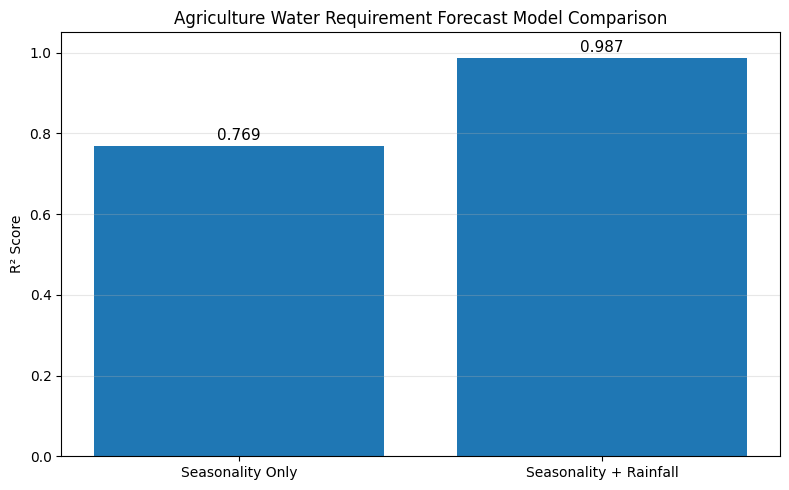

In [112]:
# ============================================================
# VISUAL: AGRICULTURE FORECAST MODEL R² COMPARISON
# ============================================================

import matplotlib.pyplot as plt

models = [
    "Seasonality Only",
    "Seasonality + Rainfall"
]

r2_values = [
    0.769,
    0.987
]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    models,
    r2_values
)

# Add values above bars
for bar, value in zip(bars, r2_values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.015,
        f"{value:.3f}",
        ha="center",
        fontsize=11
    )

plt.title("Agriculture Water Requirement Forecast Model Comparison")
plt.ylabel("R² Score")
plt.ylim(0, 1.05)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

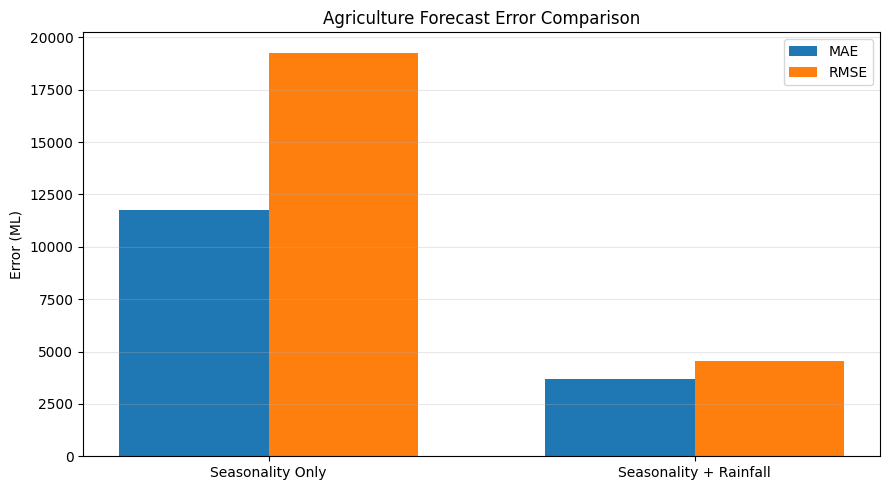

In [113]:
# ============================================================
# VISUAL: MAE AND RMSE MODEL COMPARISON
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

models = [
    "Seasonality Only",
    "Seasonality + Rainfall"
]

mae_values = [
    11768.513,
    3688.784
]

rmse_values = [
    19273.944,
    4535.310
]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(9, 5))

bars1 = plt.bar(
    x - width/2,
    mae_values,
    width,
    label="MAE"
)

bars2 = plt.bar(
    x + width/2,
    rmse_values,
    width,
    label="RMSE"
)

plt.xticks(x, models)

plt.ylabel("Error (ML)")
plt.title("Agriculture Forecast Error Comparison")

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [114]:
# ============================================================
# STEP 10: 2026 RAINFALL SCENARIO
# Historical monthly median method
# ============================================================

rain_history = monthly[
    ["Date", "Rainfall_mm"]
].copy()

rain_history["Date"] = pd.to_datetime(
    rain_history["Date"]
)

rain_history["Month"] = (
    rain_history["Date"].dt.month
)

# Historical median rainfall for each calendar month
monthly_rainfall_median = (
    rain_history
    .groupby("Month")["Rainfall_mm"]
    .median()
)


# Create Jan-Dec 2026
future_2026 = pd.DataFrame({
    "Date": pd.date_range(
        start="2026-01-01",
        end="2026-12-01",
        freq="MS"
    )
})

future_2026["Year"] = 2026
future_2026["Month"] = (
    future_2026["Date"].dt.month
)

future_2026["Forecast_Rainfall_mm"] = (
    future_2026["Month"]
    .map(monthly_rainfall_median)
)


# Seasonal features
future_2026["Month_Sin"] = np.sin(
    2 * np.pi * future_2026["Month"] / 12
)

future_2026["Month_Cos"] = np.cos(
    2 * np.pi * future_2026["Month"] / 12
)


print("2026 RAINFALL SCENARIO")
print("----------------------")

display(
    future_2026[
        [
            "Date",
            "Forecast_Rainfall_mm"
        ]
    ].round(2)
)

2026 RAINFALL SCENARIO
----------------------


,Date,Forecast_Rainfall_mm
0,2026-01-01,10.9
1,2026-02-01,1.4
2,2026-03-01,12.4
3,2026-04-01,18.2
4,2026-05-01,13.5
5,2026-06-01,10.5
6,2026-07-01,14.2
7,2026-08-01,18.6
8,2026-09-01,28.0
9,2026-10-01,94.3


In [115]:
# ============================================================
# STEP 11: FINAL AGRICULTURE MODEL + 2026 FORECAST
# ============================================================

# Train final model using all available historical observations
X_agri_final = agri_with_climate[
    agri_features_v2
]

y_agri_final = agri_with_climate[
    "Agri_Net_Water_Corrected_ML"
]


final_agri_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

final_agri_model.fit(
    X_agri_final,
    y_agri_final
)


# Prepare 2026 model inputs
X_2026_agri = future_2026[
    [
        "Year",
        "Month_Sin",
        "Month_Cos",
        "Forecast_Rainfall_mm"
    ]
].copy()

# Match training feature name
X_2026_agri = X_2026_agri.rename(
    columns={
        "Forecast_Rainfall_mm":
        "Rainfall_mm"
    }
)


# Predict
future_2026["Predicted_Agriculture_ML"] = (
    final_agri_model.predict(
        X_2026_agri
    )
)

# Water requirement cannot be negative
future_2026["Predicted_Agriculture_ML"] = (
    future_2026[
        "Predicted_Agriculture_ML"
    ].clip(lower=0)
)


print("2026 AGRICULTURE WATER REQUIREMENT FORECAST")
print("-------------------------------------------")

display(
    future_2026[
        [
            "Date",
            "Forecast_Rainfall_mm",
            "Predicted_Agriculture_ML"
        ]
    ].round(2)
)

2026 AGRICULTURE WATER REQUIREMENT FORECAST
-------------------------------------------


,Date,Forecast_Rainfall_mm,Predicted_Agriculture_ML
0,2026-01-01,10.9,125366.40
1,2026-02-01,1.4,127289.76
2,2026-03-01,12.4,39086.48
3,2026-04-01,18.2,70244.09
4,2026-05-01,13.5,70571.26
5,2026-06-01,10.5,19315.56
6,2026-07-01,14.2,8293.87
7,2026-08-01,18.6,8659.13
8,2026-09-01,28.0,32686.02
9,2026-10-01,94.3,32853.45


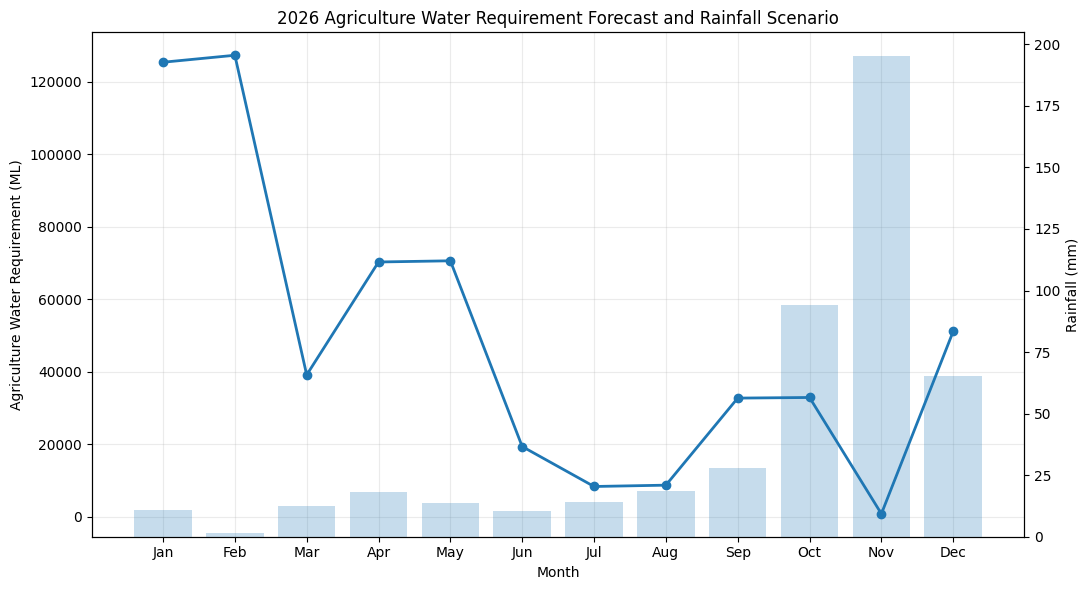

In [118]:
# ============================================================
# 2026 AGRICULTURE WATER REQUIREMENT + RAINFALL VISUAL
# ============================================================

import matplotlib.pyplot as plt

plot_2026 = future_2026.copy()

plot_2026["Month_Name"] = (
    plot_2026["Date"].dt.strftime("%b")
)

fig, ax1 = plt.subplots(figsize=(11, 6))

# Agriculture requirement
ax1.plot(
    plot_2026["Month_Name"],
    plot_2026["Predicted_Agriculture_ML"],
    marker="o",
    linewidth=2,
    label="Predicted Agriculture Requirement"
)

ax1.set_xlabel("Month")
ax1.set_ylabel("Agriculture Water Requirement (ML)")
ax1.grid(alpha=0.25)

# Rainfall on second axis
ax2 = ax1.twinx()

ax2.bar(
    plot_2026["Month_Name"],
    plot_2026["Forecast_Rainfall_mm"],
    alpha=0.25,
    label="Rainfall Scenario"
)

ax2.set_ylabel("Rainfall (mm)")

plt.title(
    "2026 Agriculture Water Requirement Forecast and Rainfall Scenario"
)

fig.tight_layout()
plt.show()